# GIS Project

## Library Imports

In [ ]:
# GIS and Spatial Data Libraries
import rasterio
from rasterio.transform import xy
from rasterio.warp import transform_bounds
from rasterio.plot import show

import geopandas as gpd
import shapely
from shapely.geometry import Point
from shapely.geometry import box
import rioxarray
import xrspatial as xspd

from pyproj import Transformer
import pip 
import json

# Data Analysis and Machine Learning
import numpy as np
import pandas as pd
from scipy.stats import skew

# Data Visualization
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource

# Print verification to ensure everything loaded without errors
print("All libraries imported successfully")

All libraries imported successfully


## Data Load

In [ ]:
# File Loading Validation
from pathlib import Path
import os

# Check for File Load Errors
print("Working directory:", Path.cwd())
print("Python executable:", os.sys.executable)
print("Datasets folder exists:", Path("Datasets").exists())

Working directory: c:\Users\matil\Documents\GitHub\GIS-Project
Python executable: c:\Users\matil\AppData\Local\Programs\Python\Python313\python.exe
Datasets folder exists: True


In [ ]:
# Load .tif
tif_path = r"Datasets\rasters_CAMRDEM\output_be.tif"
src = rasterio.open(r"Datasets\rasters_CAMRDEM\output_be.tif")

# Raster Metadata
with rasterio.open(tif_path) as src:
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Width:", src.width)
    print("Height:", src.height)
    print(src.tags())
    #print(src.crs.to_wkt())
    print("Resolution:", src.res)
    print("NoData value:", src.nodata)
    print("Transform:", src.transform)

    bounds_4326 = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds
    )

    print("WGS84 bounds:", bounds_4326)

CRS: EPSG:3979
Bounds: BoundingBox(left=-1980000.0, bottom=473550.0, right=-1960020.0, top=500400.0)
Width: 666
Height: 895
{'AREA_OR_POINT': 'Area'}
Resolution: (30.0, 30.0)
NoData value: -32767.0
Transform: | 30.00, 0.00,-1980000.00|
| 0.00,-30.00, 500400.00|
| 0.00, 0.00, 1.00|
WGS84 bounds: (-123.29291260026993, 49.25527457420543, -122.8853009908351, 49.55076853448343)


In [ ]:
# Extract bounds
west, south, east, north = bounds_4326

print("West:", west)
print("South:", south)
print("East:", east)
print("North:", north)

geometry = box(west, south, east, north)

geojson = {
    "type": "FeatureCollection",
    "features": [{
        "type": "Feature",
        "properties": {},
        "geometry": geometry.__geo_interface__
    }]
}

with open("dem_AOI.geojson", "w") as f:
    json.dump(geojson, f, indent=2)

West: -123.29291260026993
South: 49.25527457420543
East: -122.8853009908351
North: 49.55076853448343


In [ ]:
# Read band 1
src = rasterio.open(r"Datasets\rasters_CAMRDEM\output_be.tif")
with rasterio.open(tif_path) as src:
    elevation = src.read(1)
    elevation_transform = src.transform
    elevation_crs = src.crs

    print("Array type:", type(elevation))
    print("Array size:", elevation.size)
    print("Array shape:", elevation.shape)
    print("Minimum value:", elevation.min())
    print("Maximum value:", elevation.max())

Array type: <class 'numpy.ndarray'>
Array size: 596070
Array shape: (895, 666)
Minimum value: -32767.0
Maximum value: 1503.917


## Dataset Transform

In [56]:
# Transform Coordinates
transformer = Transformer.from_crs(
    src.crs,
    "EPSG:4326",
    always_xy=True
)

# Transform pixel coordinates (row, col) to spatial coordinates (x, y)/(lon, lat) Sample
x, y = xy(src.transform, 100, 200)
#print(x, y)
#print(elevation[100, 200])

lon, lat = transformer.transform(x, y)
#print(lon, lat)

x1, y1 = xy(src.transform, 100, 200) # coordinates [m]
#print(x1, y1)

lon1, lat1 = transformer.transform(x1, y1)
#print(lon1, lat1) # coordinates [deg]

## 2D Data Plot

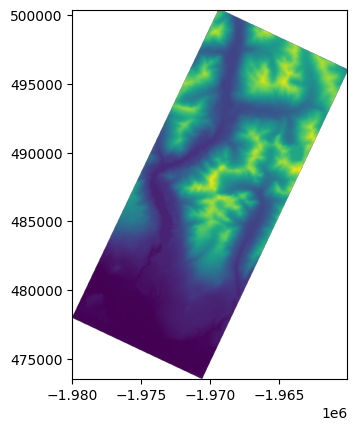

<Axes: >

In [ ]:
# Data Mask
mask = elevation != src.nodata
filtered = np.where(mask, elevation, np.nan)

# Data Plot
show(filtered, transform=src.transform)

## Data Distribution

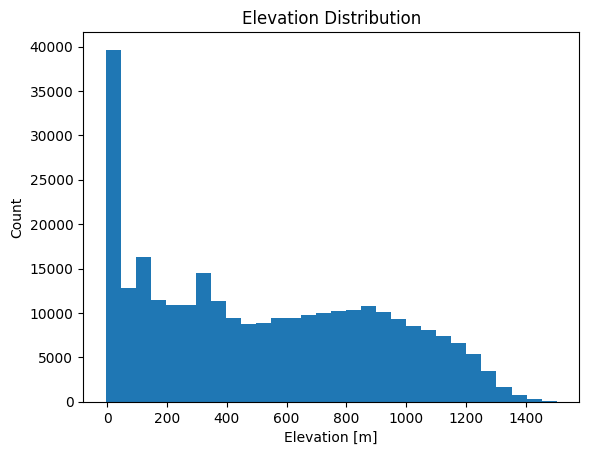

Array shape: (895, 666)
Array size: 596070
Minimum value: -5.4634385
Maximum value: 1503.917
Mean value: 523.2575
Median value: 481.55276
Standard deviation: 391.07172
Skewness: 0.26910743


In [ ]:
# Elevation Distribution
fil_flat = filtered.flatten()

plt.hist(fil_flat, bins=30)
plt.title("Elevation Distribution")
plt.xlabel("Elevation [m]")
plt.ylabel("Count")
plt.show()

# Distribution Statistics
print("Array shape:", filtered.shape)
print("Array size:", filtered.size)
print("Minimum value:", np.nanmin(filtered))
print("Maximum value:", np.nanmax(filtered))
print("Mean value:", np.nanmean(filtered))
print("Median value:", np.nanmedian(filtered))
print("Standard deviation:", np.nanstd(filtered))
print("Skewness:", skew(fil_flat[~np.isnan(fil_flat)]))

## Slope Statistics

In [ ]:
# Slope Analysis 
valid_mask = elevation != src.nodata
elevation_valid = np.where(
    valid_mask,
    elevation,
    np.nan
)

dy, dx = np.gradient(elevation, 30, 30)
slope_rad = np.arctan(np.sqrt(dx**2 + dy**2))
slope_deg = np.degrees(slope_rad)

slope_valid = np.where(
    valid_mask,
    slope_deg,
    np.nan
)

print(valid_mask.shape)
print(slope_valid.shape)

(895, 666)
(895, 666)


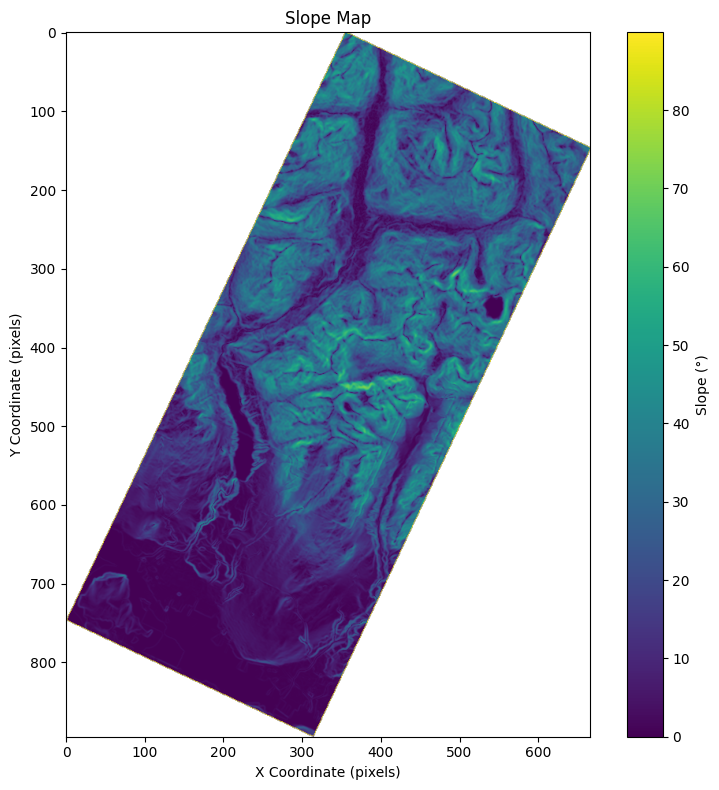

In [46]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=100)
im = ax.imshow(slope_valid, cmap="viridis")
ax.set_title("Slope Map")
ax.set_xlabel("X Coordinate (pixels)")
ax.set_ylabel("Y Coordinate (pixels)")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Slope (°)")
plt.tight_layout()
plt.show()

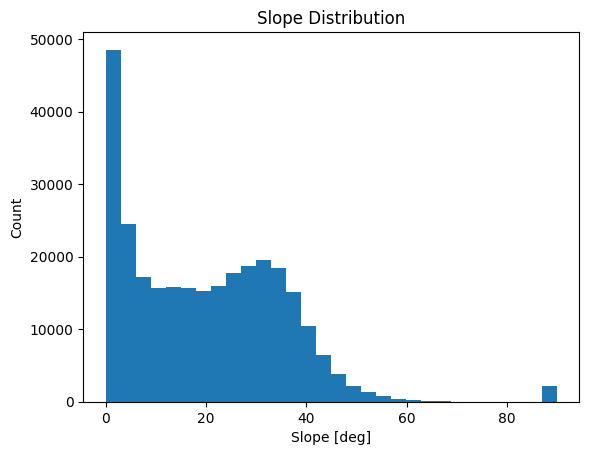

Array shape: (596070,)
Array size: 596070
Minimum value: 0.0
Maximum value: 89.929054
Mean value: 19.990324
Median value: 19.125431
Standard deviation: 15.427991
Skewness: 0.81414634


In [47]:
# Slope Distribution
slope_flat = slope_valid.flatten()

plt.hist(slope_flat[~np.isnan(slope_flat)], bins=30)
plt.title("Slope Distribution")
plt.xlabel("Slope [deg]")
plt.ylabel("Count")
plt.show()

# Slope Statistics
print("Array shape:", slope_flat.shape)
print("Array size:", slope_flat.size)
print("Minimum value:", np.nanmin(slope_flat))
print("Maximum value:", np.nanmax(slope_flat))
print("Mean value:", np.nanmean(slope_flat))
print("Median value:", np.nanmedian(slope_flat))
print("Standard deviation:", np.nanstd(slope_flat))
print("Skewness:", skew(slope_flat[~np.isnan(slope_flat)]))

### Maximum Slope

## Aspect?

## Terrain Map?

## Terrain Analysis and Masks

In [48]:
# Slope Masks
slope_under_30_deg = np.where(
    slope_valid < 30,
    slope_valid,
    np.nan
)

slope_30_60_deg = np.where(
    (slope_valid >= 30) & (slope_valid < 60),
    slope_valid,
    np.nan
)

slope_greater_60_deg = np.where(
    slope_valid >= 60,
    slope_valid,
    np.nan
)

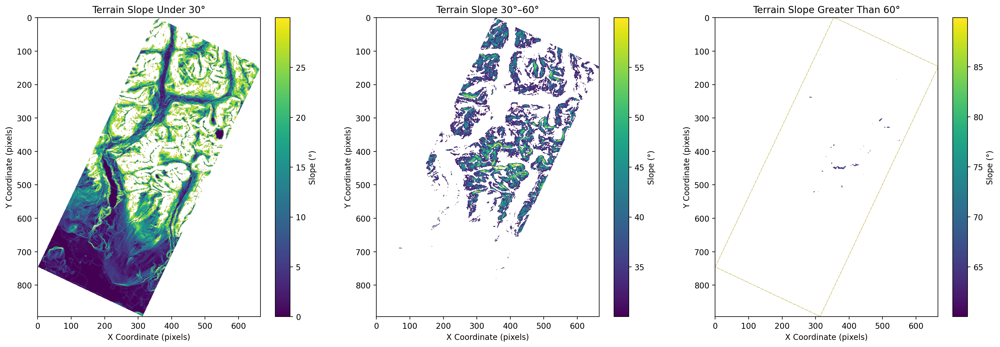

In [49]:
## Slope Plots
slope_labels = [
    "Terrain Slope Under 30°",
    "Terrain Slope 30°–60°",
    "Terrain Slope Greater Than 60°"
]

slope_rasters = [
    slope_under_30_deg,
    slope_30_60_deg,
    slope_greater_60_deg
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=200)

for ax, slope_data, label in zip(axes, slope_rasters, slope_labels):
    im = ax.imshow(slope_data, cmap="viridis")
    ax.set_title(label)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Slope (°)")

plt.tight_layout()
plt.show()

In [50]:
# Elevation Masks
elevation_under_500 = elevation_valid > 100 
elevation_under_500 = np.where(
    elevation_valid < 500,
    elevation_valid,
    np.nan
)

elevation_500_1000 = np.where(
     (elevation_valid >= 500) & (elevation_valid < 1000),
    elevation_valid,
    np.nan
)

elevation_1000_1500 = np.where(
     (elevation_valid >= 1000) & (elevation_valid < 1500),
    elevation_valid,
    np.nan
)

elevation_greater_1500 = np.where(
    elevation_valid >= 1500,
    elevation_valid,
    np.nan
)

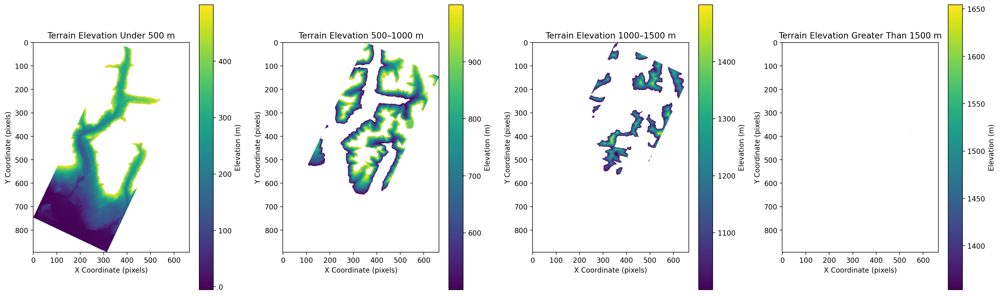

In [51]:
# Elevation Plots
elevation_labels = [
    "Terrain Elevation Under 500 m",
    "Terrain Elevation 500–1000 m",
    "Terrain Elevation 1000–1500 m",
    "Terrain Elevation Greater Than 1500 m"
]

elevation_rasters = [
    elevation_under_500,
    elevation_500_1000,
    elevation_1000_1500,
    elevation_greater_1500
]

fig, axes = plt.subplots(1, 4, figsize=(20, 6), dpi=200)

for ax, elevation_data, label in zip(axes, elevation_rasters, elevation_labels):
    im = ax.imshow(elevation_data, cmap="viridis")
    ax.set_title(label)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Elevation (m)")

plt.tight_layout()
plt.show()

## Combined Masks

In [52]:
# Sample Combined Masks
combined_raster1 = np.where(
    ~np.isnan(slope_under_30_deg) & ~np.isnan(elevation_under_500), 
    elevation_under_500, 
    np.nan 
) 

combined_raster2 = np.where( 
    ~np.isnan(elevation_under_500) & ~np.isnan(slope_under_30_deg), 
    slope_under_30_deg, 
    np.nan
)

# 12 Combined Sets
params_slope = [slope_under_30_deg, slope_30_60_deg, slope_greater_60_deg]
params_elevation = [elevation_under_500, elevation_500_1000, elevation_1000_1500, elevation_greater_1500]
elevation_rasters = []
slope_rasters = []

for slope_layer in params_slope:
    for elevation_layer in params_elevation:

        valid_new_mask = ~np.isnan(slope_layer) & ~np.isnan(elevation_layer)

        slope_mask = np.where(valid_new_mask, slope_layer, np.nan)
        slope_rasters.append(slope_mask)

        elevation_mask = np.where(valid_new_mask, elevation_layer, np.nan)
        elevation_rasters.append(elevation_mask)

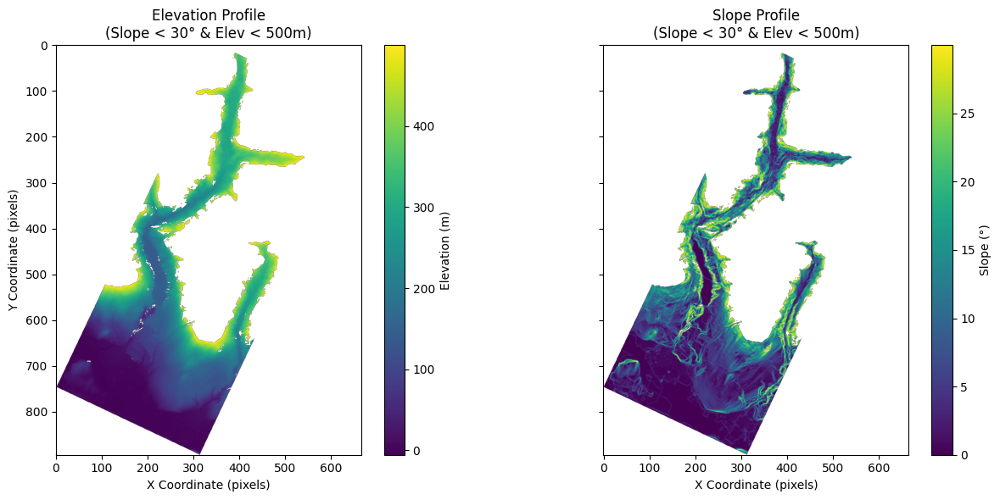

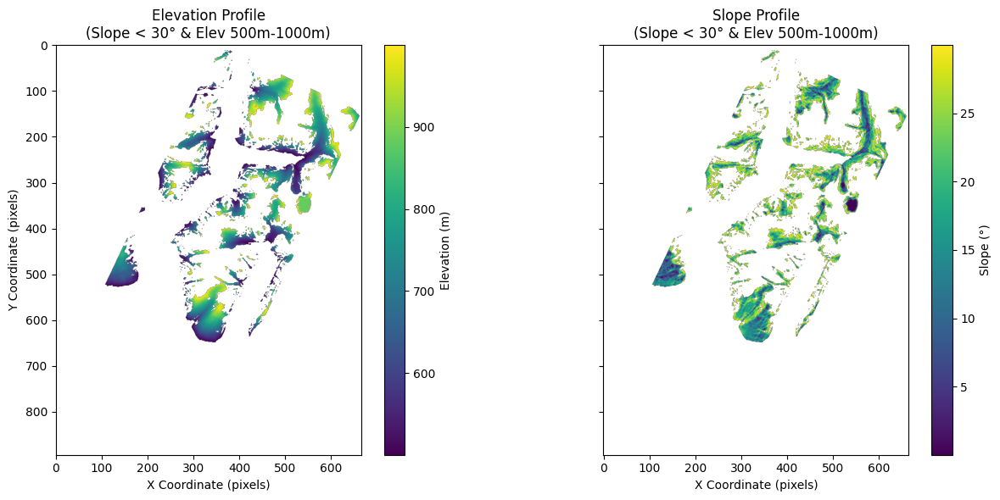

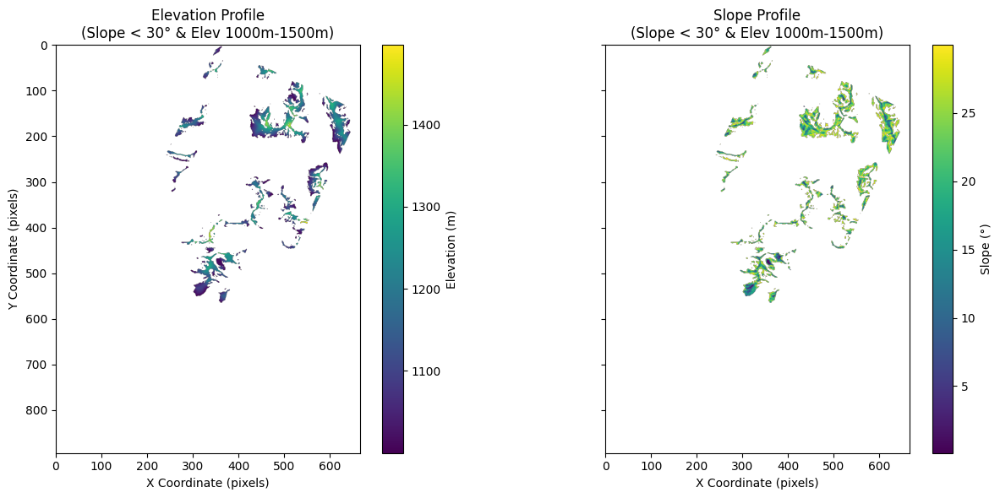

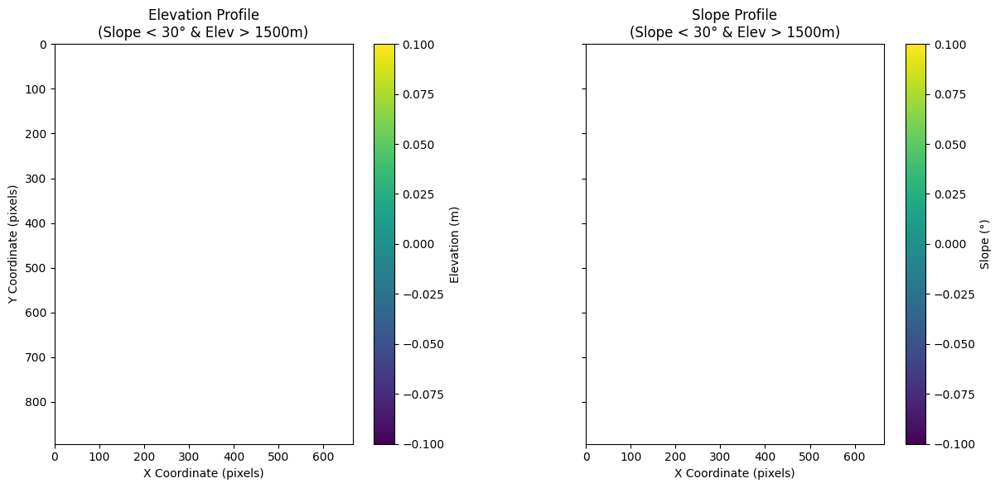

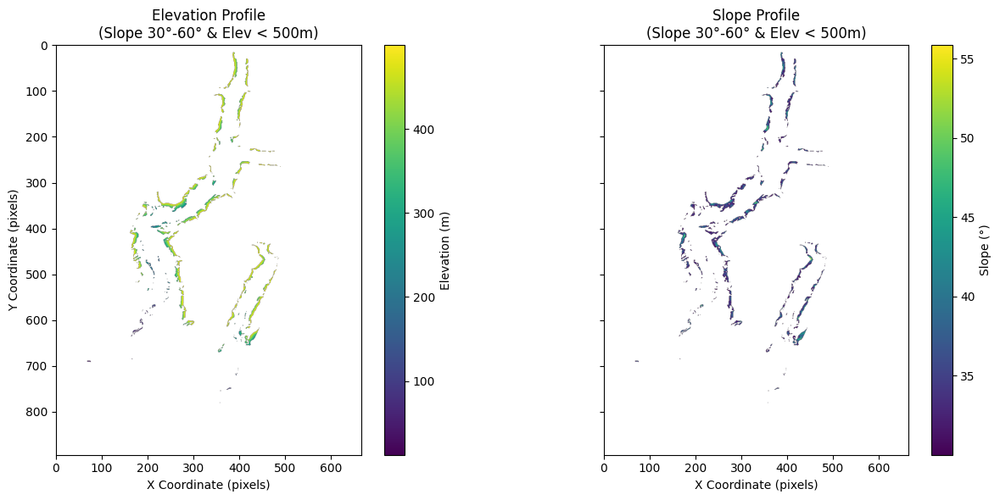

...

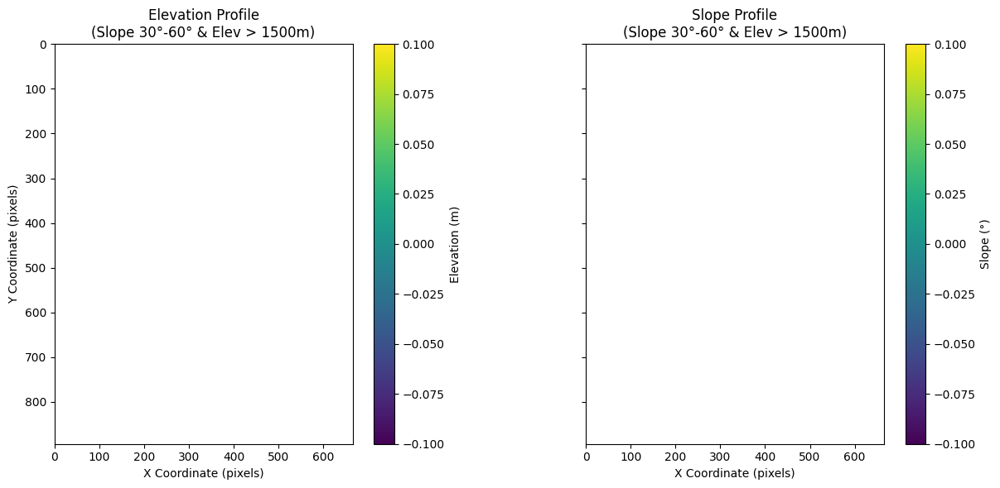

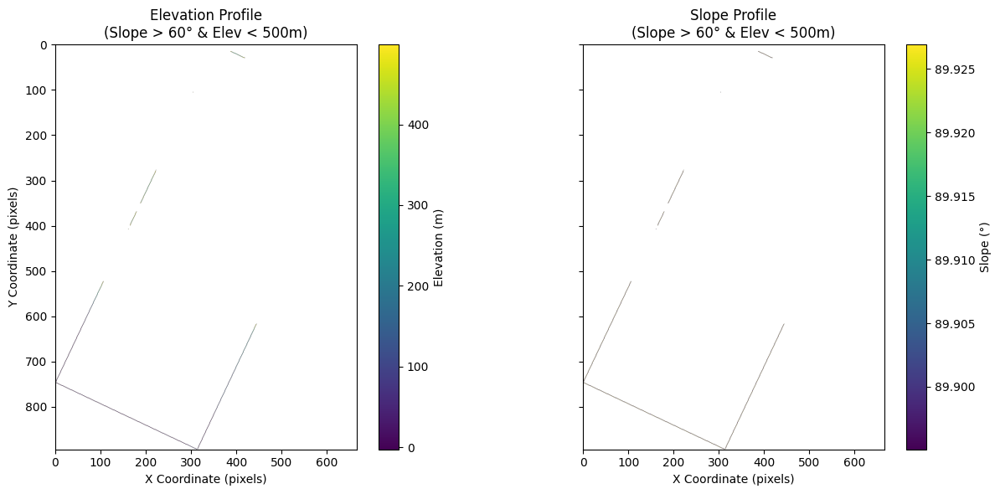

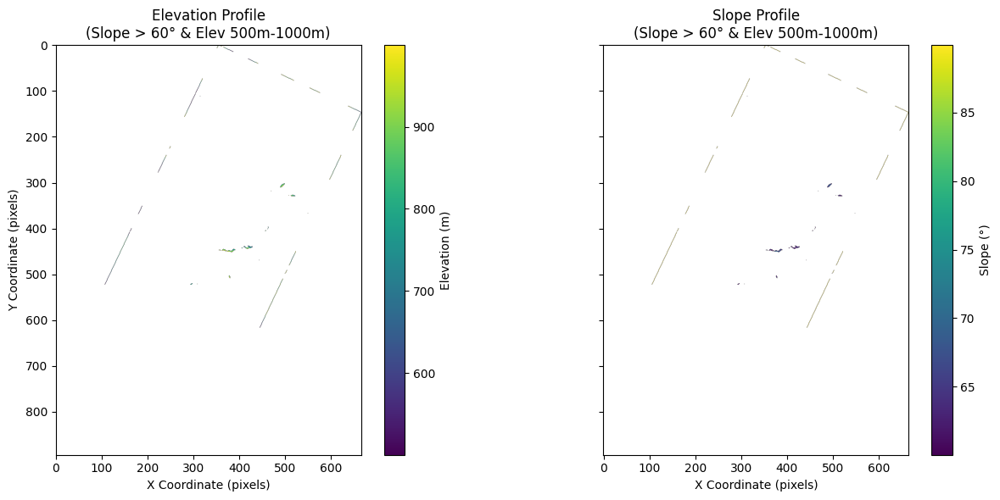

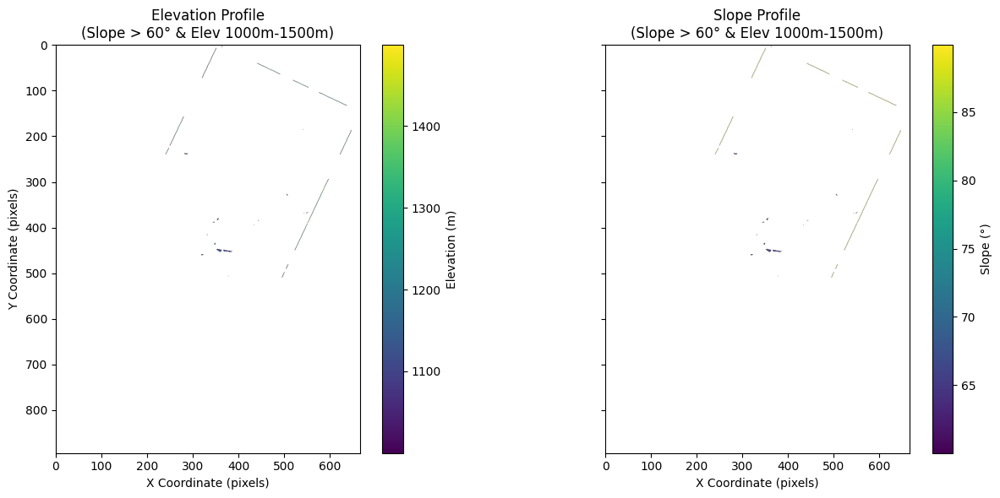

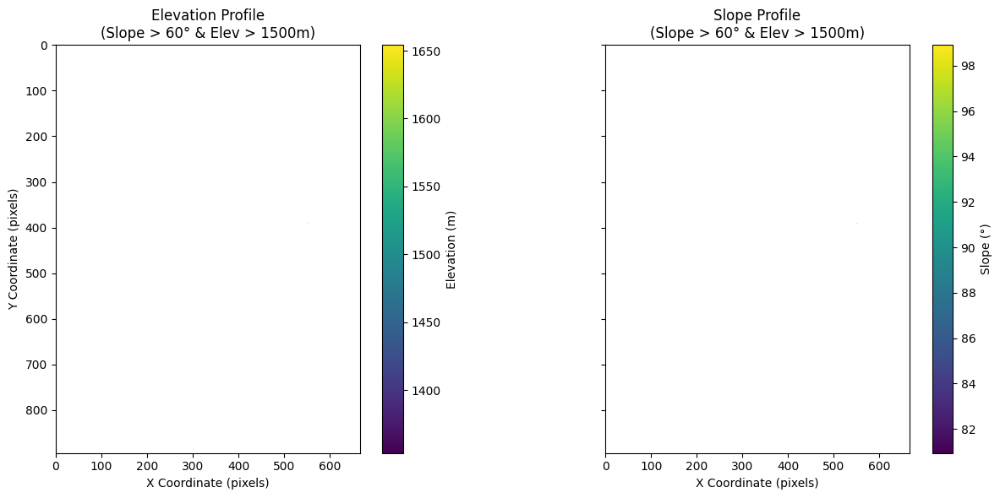

In [53]:
# Combined Plots
slope_labels = ["Slope < 30°", "Slope 30°-60°", "Slope > 60°"]
elevation_labels = ["Elev < 500m", "Elev 500m-1000m", "Elev 1000m-1500m", "Elev > 1500m"]

index = 0

for s_label in slope_labels:
    for e_label in elevation_labels:

        elevation_data = elevation_rasters[index]
        slope_data = slope_rasters[index]

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

        # Elevation Plots
        im1 = ax1.imshow(elevation_data, cmap='viridis')
        ax1.set_title(f"Elevation Profile\n({s_label} & {e_label})", fontsize=12)
        ax1.set_xlabel("X Coordinate (pixels)")
        ax1.set_ylabel("Y Coordinate (pixels)")
        cbar1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
        cbar1.set_label("Elevation (m)") 

        # Slope Plots
        im2 = ax2.imshow(slope_data, cmap='viridis')
        ax2.set_title(f"Slope Profile\n({s_label} & {e_label})", fontsize=12)
        ax2.set_xlabel("X Coordinate (pixels)")

        cbar2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
        cbar2.set_label("Slope (°)") 

        plt.tight_layout()
        plt.show()

        index += 1

# Statistical Analysis

In [54]:
window_size = 50
patch1 = []


for row in range(0, elevation_valid.shape[0] - window_size):
    for col in range(0, elevation_valid.shape[1] - window_size):

        patch1 = elevation_valid[
            row:row + window_size,
            col:col + window_size
        ]

        if np.isfinite(patch1).all():
            print("Found:", row, col)
            break

np.isfinite(patch1).all()

Found: 18 345
Found: 19 345
Found: 20 344
Found: 21 344
Found: 22 343
Found: 23 343
Found: 24 342
Found: 25 342
Found: 26 341
Found: 27 341
Found: 28 340
Found: 29 340
Found: 30 340
Found: 31 339
Found: 32 339
Found: 33 338
Found: 34 338
Found: 35 337
Found: 36 337
Found: 37 336
Found: 38 336
Found: 39 335
Found: 40 335
Found: 41 334
Found: 42 334
Found: 43 333
Found: 44 333
Found: 45 332
Found: 46 332
Found: 47 331
Found: 48 331
Found: 49 331
Found: 50 330
Found: 51 330
Found: 52 329
Found: 53 329
Found: 54 328
Found: 55 328
Found: 56 327
Found: 57 327
Found: 58 326
Found: 59 326
Found: 60 325
Found: 61 325
Found: 62 324
Found: 63 324
Found: 64 323
Found: 65 323
Found: 66 322
Found: 67 322
Found: 68 322
Found: 69 321
Found: 70 321
Found: 71 320
Found: 72 320
Found: 73 319
Found: 74 319
Found: 75 318
Found: 76 318
Found: 77 317
Found: 78 317
Found: 79 316
Found: 80 316
Found: 81 315
Found: 82 315
Found: 83 314
Found: 84 314
Found: 85 313
Found: 86 313
Found: 87 313
Found: 88 312
Found:

np.False_

In [55]:

# Select a contiguous, valid patch of your DEM
patch = elevation_valid[100:150, 100:150]


print("Shape:", patch.shape)
print("Finite pixels:", np.isfinite(patch).sum())
print("Total pixels:", patch.size)
print("Min:", np.nanmin(patch))
print("Max:", np.nanmax(patch))

print(max(elevation_valid[np.isfinite(elevation_valid)]))

if np.isfinite(patch).all():
    patch_centered = patch - np.mean(patch)
    fft_result = np.fft.fft2(patch_centered)
    fft_shifted = np.fft.fftshift(fft_result)
    magnitude = np.abs(fft_shifted)

# Remove the mean


# Display on a logarithmic scale
plt.imshow(np.log1p(magnitude))
plt.title("2D FFT Magnitude Spectrum")
plt.colorbar()
plt.show()

Shape: (50, 50)
Finite pixels: 0
Total pixels: 2500
Min: nan
Max: nan
1503.917


C:\Users\matil\AppData\Local\Temp\ipykernel_16192\3503498320.py:8: RuntimeWarning: All-NaN slice encountered
  print("Min:", np.nanmin(patch))
C:\Users\matil\AppData\Local\Temp\ipykernel_16192\3503498320.py:9: RuntimeWarning: All-NaN slice encountered
  print("Max:", np.nanmax(patch))


NameError: name 'magnitude' is not defined

## Raster Statistics?

In [ ]:


cell_count = np.sum(~np.isnan(slope_under_30_deg))
area_km2 = cell_count * 30 * 30 / 1_000_000

print(cell_count, area_km2)

205498 184.9482


## Slope Variability?

In [ ]:
from scipy.ndimage import generic_filter

def local_std(window):
    valid = window[~np.isnan(window)]

    if len(valid) == 0:
        return np.nan

    return np.std(valid)

slope_variability = generic_filter(
    slope_valid,
    local_std,
    size=30
)

In [ ]:
print(np.sum(np.isnan(slope_variability)))

In [ ]:
plt.imshow(slope_variability)
plt.colorbar(label="Local slope variation [degrees]")
plt.title("Local Slope Variability")
plt.show()

In [ ]:
max_variation = np.nanmax(slope_variability)
print(max_variation)

row, col = np.unravel_index(
    np.nanargmax(slope_variability),
    slope_variability.shape
)
print(row, col)
print(elevation[739,0])
print(nodata_val)

In [ ]:
variation_flat = slope_variability.flatten()
variation_valid = variation_flat[~np.isnan(variation_flat)]
threshold = np.percentile(variation_valid, 99)
top_1_percent_mask = slope_variability >= threshold

top_1_percent = np.where(
    top_1_percent_mask,
    slope_variability,
    np.nan
)

In [ ]:

plt.imshow(top_1_percent)
plt.colorbar(label="Local slope variability")
plt.title("Top 1% Most Variable Terrain")
plt.show()

In [ ]:
rows, cols = np.where(top_1_percent_mask)

print(rows)
print(cols)

print(elevation[894,323])

In [ ]:
print("DEM nodata:", src.nodata)
print("DEM min:", np.min(elevation))
print("DEM nodata count:", np.sum(elevation == src.nodata))

print("Slope min:", np.nanmin(slope_valid))
print("Slope NaN count:", np.sum(np.isnan(slope_valid)))

## Band Export .tif to QGIS

In [3]:
slope_unique_rasters = {
    "slope_under_30_deg": slope_under_30_deg,
    "slope_30_60_deg": slope_30_60_deg,
    "slope_greater_60_deg": slope_greater_60_deg
}

elevation_unique_rasters = {
    "elevation_under_500": elevation_under_500,
    "elevation_500_1000": elevation_500_1000,
    "elevation_1000_1500": elevation_1000_1500,
    "elevation_greater_1500": elevation_greater_1500
}

slope_names = [ "slope_under_30_deg", "slope_30_60_deg", "slope_greater_60_deg"]
elevation_names = ["elevation_under_500", "elevation_500_1000", "elevation_1000_1500", "elevation_greater_1500"]
combined_unique_rasters = {}

index = 0

for slope_name in slope_names:
    for elevation_name in elevation_names:

        combined_unique_rasters[
            f"{elevation_name}_showing_{slope_name}_gradient"
        ] = slope_rasters[index]

        combined_unique_rasters[
                    f"{slope_name}_showing_{elevation_name}_gradient"
                ] = elevation_rasters[index]

        index += 1

NameError: name 'slope_under_30_deg' is not defined

In [2]:
export_bands = {}
export_bands.update(list(slope_unique_rasters.items())[:3])
export_bands.update(list(elevation_unique_rasters.items())[:4])
export_bands.update(list(combined_unique_rasters.items())[:6])
print(len(export_bands))

NameError: name 'slope_unique_rasters' is not defined

In [1]:
print(export_bands)

NameError: name 'export_bands' is not defined

In [ ]:
output_path = r"Data Export\export_bands.tif"

with rasterio.open(output_path, "w",
                   driver="GTiff",
                   height=src.height,
                   width=src.width,
                   count=len(export_bands),
                   dtype="float32",
                   crs=src.crs,
                   transform=src.transform,
                   nodata=np.nan) as dst:

    for band_number, (name, raster) in enumerate(export_bands.items(), start=1):
        dst.write(raster.astype("float32"), band_number)
        dst.set_band_description(band_number, name)

In [ ]:
output_path2 = r"Data Export\export_bands2.tif"

export_bands2 = {}
export_bands2.update(list(slope_unique_rasters.items())[:3])

with rasterio.open(output_path2, "w",
                   driver="GTiff",
                   height=src.height,
                   width=src.width,
                   count=len(export_bands2),
                   dtype="float32",
                   crs=src.crs,
                   transform=src.transform,
                   nodata=np.nan) as dst:

    for band_number, (name, raster) in enumerate(export_bands2.items(), start=1):
        dst.write(raster.astype("float32"), band_number)
        dst.set_band_description(band_number, name)

## Blender Export ?? fix sizing and use 10m reproject instead??

In [ ]:
# Flatten the elevation array and filter out NaN values
rows, cols = np.where(np.isfinite(elevation_valid))

x_clean, y_clean = xy(elevation_transform, rows, cols)
z_clean = elevation_valid[rows, cols]
x_clean = np.asarray(x_clean)
y_clean = np.asarray(y_clean)

# Repositon coordinates to Blender origin
origin_x = (x_clean.min() + x_clean.max()) / 2
origin_y = (y_clean.min() + y_clean.max()) / 2
origin_z = z_clean.min()

scale = 100.0  

x_blender = (x_clean - origin_x) / scale
y_blender = (y_clean - origin_y) / scale
z_blender = (z_clean - origin_z) / scale

blender_points = np.column_stack((x_blender, y_blender, z_blender))

print("Cleaned X coordinates:", x_blender)
print("Cleaned Y coordinates:", y_blender)
print("Cleaned Z values:", z_blender)
print(x_blender.shape, y_blender.shape, z_blender.shape)

Cleaned X coordinates: [ 6.45  6.75  7.05 ... -5.85 -5.55 -5.85]
Cleaned Y coordinates: [ 134.1  134.1  134.1 ... -133.8 -133.8 -134.1]
Cleaned Z values: [8.7506075 8.797502  8.883633  ... 0.6188633 0.5860374 0.6770249]
(286497,) (286497,) (286497,)


In [ ]:
exported_columns = np.column_stack((x_blender, y_blender, z_blender))

np.savetxt(
    r"Data Export\terrain_points.csv",
    exported_columns,
    delimiter=",",
    header="x,y,z",
    comments=""
)

## Sentinel Metadata and Cleaning

In [ ]:
# Data Loading and Metadata Extraction
B08_path = r"Datasets\sentinel2_L2A_10m\T10UDV_20260918T191831_B08_10m.jp2"
B04_path = r"Datasets\sentinel2_L2A_10m\T10UDV_20260918T191831_B04_10m.jp2"

with rasterio.open(B04_path) as red_src:
    red_band = red_src.read(1).astype(np.float32)
    red_transform = red_src.transform
    red_crs = red_src.crs

    print("Red band CRS:", red_src.crs)
    print("Red band transform:", red_src.transform)
    print("Red band shape:", red_src.shape)
    print("Red band bounds:", red_src.bounds)
    print("Red band nodata:", red_src.nodata)
    print("Red band tags:", red_src.tags())

with rasterio.open(B08_path) as nir_src:
    nir_band = nir_src.read(1).astype(np.float32)
    nir_transform = nir_src.transform
    nir_crs = nir_src.crs
    
    print("NIR band CRS:", nir_src.crs)
    print("NIR band transform:", nir_src.transform)
    print("NIR band shape:", nir_src.shape)
    print("NIR band bounds:", nir_src.bounds)
    print("NIR band nodata:", nir_src.nodata)
    print("NIR band tags:", nir_src.tags())

Red band CRS: EPSG:32610
Red band transform: | 10.00, 0.00, 399960.00|
| 0.00,-10.00, 5500020.00|
| 0.00, 0.00, 1.00|
Red band shape: (10980, 10980)
Red band bounds: BoundingBox(left=399960.0, bottom=5390220.0, right=509760.0, top=5500020.0)
Red band nodata: None
Red band tags: {}
NIR band CRS: EPSG:32610
NIR band transform: | 10.00, 0.00, 399960.00|
| 0.00,-10.00, 5500020.00|
| 0.00, 0.00, 1.00|
NIR band shape: (10980, 10980)
NIR band bounds: BoundingBox(left=399960.0, bottom=5390220.0, right=509760.0, top=5500020.0)
NIR band nodata: None
NIR band tags: {}


In [ ]:
# Grab metadata from the XML file
from xml.etree import ElementTree as ET

xml_path = r"Datasets\S2A_MSIL2A_20260918T191831_N0512_R056_T10UDV_20260919T014720.SAFE (1)\S2A_MSIL2A_20260918T191831_N0512_R056_T10UDV_20260919T014720.SAFE\MTD_MSIL2A.xml"
root = ET.parse(xml_path).getroot()

def tag_name(tag):
    return tag.split("}")[-1]

for elem in root.iter():
    name = tag_name(elem.tag)
    if name in {"SPECIAL_VALUE_TEXT", "SPECIAL_VALUE_INDEX"}:
        print(name, "=", elem.text)

for elem in root.iter():
    name = tag_name(elem.tag)
    if name == "BOA_QUANTIFICATION_VALUE":
        print("BOA_QUANTIFICATION_VALUE =", elem.text)
    if name == "BOA_ADD_OFFSET":
        print("BOA_ADD_OFFSET =", elem.text)

SPECIAL_VALUE_TEXT = NODATA
SPECIAL_VALUE_INDEX = 0
SPECIAL_VALUE_TEXT = SATURATED
SPECIAL_VALUE_INDEX = 65535
BOA_QUANTIFICATION_VALUE = 10000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000
BOA_ADD_OFFSET = -1000


## Sentinel BOA Correction

In [ ]:
# Data Mask
special_value = 0
valid_sentinel_mask = (red_band != special_value) & (nir_band != special_value)

print("B04 zeros:", np.sum(red_band == 0))
print("B08 zeros:", np.sum(nir_band == 0))

boa_quantification_value = 10000
boa_add_offset = -1000

# BOA Correction
red_band_masked = np.where(valid_sentinel_mask, red_band, np.nan).astype(np.float32)
nir_band_masked = np.where(valid_sentinel_mask, nir_band, np.nan).astype(np.float32)

red_band_boa_corrected = (
    red_band_masked + boa_add_offset
) / boa_quantification_value

nir_band_boa_corrected = (
    nir_band_masked + boa_add_offset
) / boa_quantification_value

# Refined Mask
denom = nir_band_boa_corrected + red_band_boa_corrected
valid_reflectance_mask = (
    np.isfinite(red_band_boa_corrected)
    & np.isfinite(nir_band_boa_corrected)
    & (red_band_boa_corrected >= 0)
    & (nir_band_boa_corrected >= 0)
    & (denom > 1e-6)
)

# NDVI
ndvi = np.full(red_band.shape, np.nan, dtype=np.float32)
np.divide(
    nir_band_boa_corrected - red_band_boa_corrected,
    denom,
    out=ndvi,
    where=valid_reflectance_mask
)

print("NDVI shape:", ndvi.shape)
print("Invalid reflectance/denominator pixels:", np.sum(~valid_reflectance_mask))
print("NDVI min:", np.nanmin(ndvi))
print("NDVI max:", np.nanmax(ndvi))
print("NDVI values outside [-1, 1]:", np.sum((ndvi < -1) | (ndvi > 1)))

B04 zeros: 68
B08 zeros: 3116
NDVI shape: (10980, 10980)
Invalid reflectance/denominator pixels: 858889
NDVI min: -1.0
NDVI max: 1.0
NDVI values outside [-1, 1]: 0


## 2D Plot

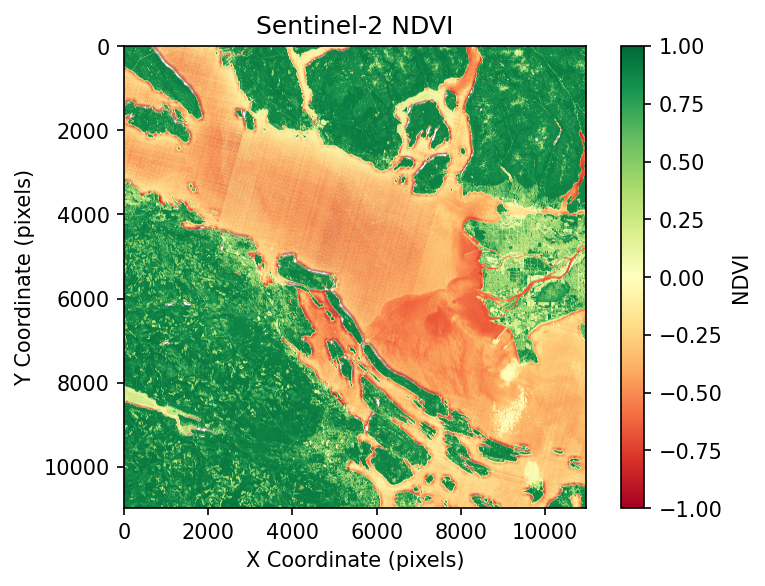

In [ ]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1) 
plt.colorbar(label="NDVI")
plt.title("Sentinel-2 NDVI")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

## SCL Correction

In [ ]:
# Data Loading and Metadata Extraction
SCL_path = r"Datasets\S2A_MS~1.SAF\S2A_MS~1.SAF\GRANULE\L2A_T1~1\IMG_DATA\R20m\T191A7~1.JP2"

with rasterio.open(SCL_path) as scl_src:
    scl = scl_src.read(1)
    scl_transform = scl_src.transform
    scl_crs = scl_src.crs
    
    print(scl_src.crs)
    print(scl_src.transform)
    print(scl_src.shape)
    print(scl_src.bounds)

EPSG:32610
| 20.00, 0.00, 399960.00|
| 0.00,-20.00, 5500020.00|
| 0.00, 0.00, 1.00|
(5490, 5490)
BoundingBox(left=399960.0, bottom=5390220.0, right=509760.0, top=5500020.0)


In [ ]:
# Reproject SCL to 10m resolution
from rasterio.warp import reproject, Resampling

scl_10m = np.empty(red_band.shape, dtype=np.float32)

reproject(
    source=scl,
    destination=scl_10m,
    src_transform=scl_transform,
    src_crs=scl_crs,
    dst_transform=red_transform,
    dst_crs=red_crs,
    dst_nodata=np.nan,
    shape=red_band.shape,
    resampling=Resampling.nearest
)

print(scl_10m.shape)

(10980, 10980)


In [ ]:
# Mask NDVI using SCL 
bad_classes = [0, 1, 2, 3, 8, 9, 10, 11]
valid_scl_mask = ~np.isin(scl_10m, bad_classes)
ndvi_clean_mask = np.where(valid_scl_mask, ndvi, np.nan)

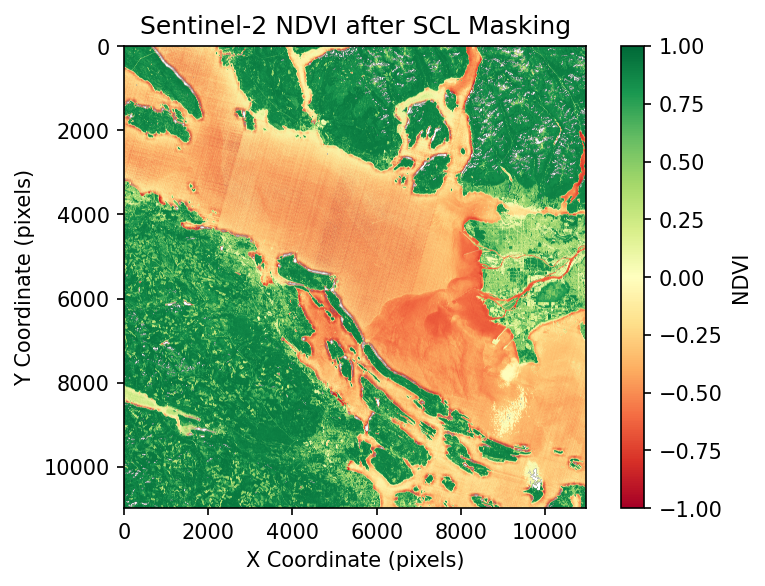

In [ ]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(ndvi_clean_mask, cmap="RdYlGn", vmin=-1, vmax=1) 
plt.colorbar(label="NDVI")
plt.title("Sentinel-2 NDVI after SCL Masking")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

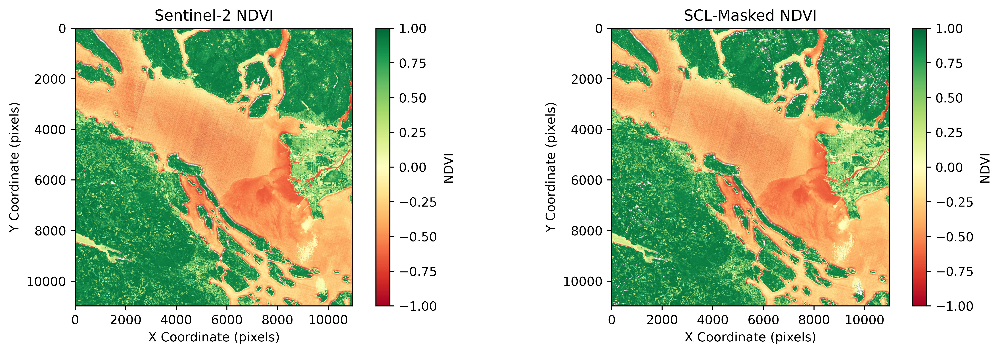

In [ ]:
#  Compare NDVI before and after SCL masking
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=500)

# Original NDVI
im1 = axes[0].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
axes[0].set_title("Sentinel-2 NDVI")
axes[0].set_xlabel("X Coordinate (pixels)")
axes[0].set_ylabel("Y Coordinate (pixels)")
fig.colorbar(im1, ax=axes[0], label="NDVI")

# SCL-masked NDVI
im2 = axes[1].imshow(ndvi_clean_mask, cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("SCL-Masked NDVI")
axes[1].set_xlabel("X Coordinate (pixels)")
axes[1].set_ylabel("Y Coordinate (pixels)")
fig.colorbar(im2, ax=axes[1], label="NDVI")

plt.tight_layout()
plt.show()

In [ ]:
# Sentinel Masking Comparison
valid_before = ~np.isnan(ndvi)
valid_after = ~np.isnan(ndvi_clean_mask)

print("Before SCL valid:", np.sum(valid_before))
print("After SCL valid:", np.sum(valid_after))
print("Pixels removed by SCL:", np.sum(valid_before & ~valid_after))

Before SCL valid: 119701511
After SCL valid: 0
Pixels removed by SCL: 119701511


## Reproject DEM to Sentinel

In [ ]:
from rasterio.warp import reproject, Resampling

elevation_reproject = np.empty(red_band.shape, dtype=np.float32)

reproject(
    source=elevation_valid,
    destination=elevation_reproject,
    src_transform=elevation_transform,
    src_crs=elevation_crs,
    dst_transform=red_transform,
    dst_crs=red_crs,
    dst_nodata=np.nan,
    shape=red_band.shape,
    resampling=Resampling.nearest
)

print(elevation_reproject.shape)
print(ndvi_clean_mask.shape)

(10980, 10980)
(10980, 10980)


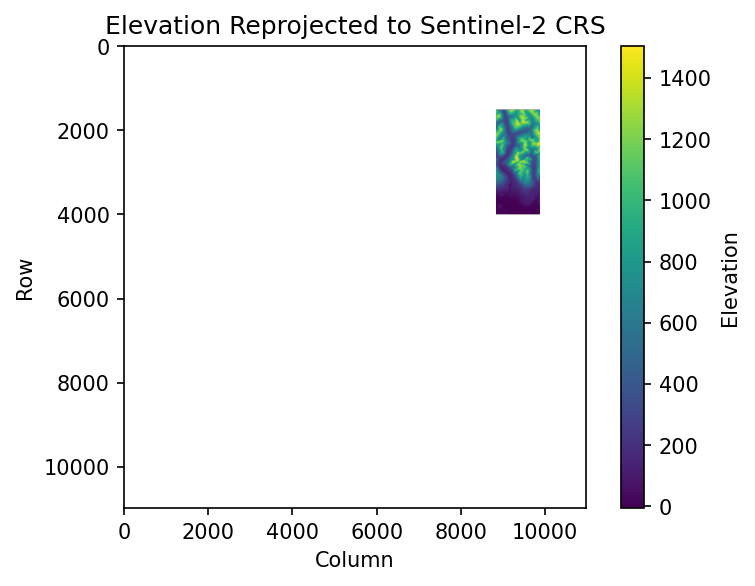

In [ ]:
# Validate reproject onto Sentinel-2 CRS visually
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
im = ax.imshow(elevation_reproject, cmap="viridis")
cbar = fig.colorbar(im, ax=ax, label="Elevation")
ax.set_title("Elevation Reprojected to Sentinel-2 CRS")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
plt.show()

In [ ]:
# Crop the reprojected DEM and NDVI to the same bounding box of valid data
valid_dem = np.isfinite(elevation_reproject)
rows, cols = np.where(valid_dem)

if rows.size == 0:
    raise ValueError("elevation_reproject contains no finite data")

row0, row1 = rows.min(), rows.max() + 1  
col0, col1 = cols.min(), cols.max() + 1
elev_crop = elevation_reproject[row0:row1, col0:col1]
ndvi_crop = ndvi_clean_mask[row0:row1, col0:col1]

print("DEM footprint rows:", row0, "to", row1 - 1)
print("DEM footprint columns:", col0, "to", col1 - 1)
print("Cropped shapes:", elev_crop.shape, ndvi_crop.shape)

# Keep the axes in original Sentinel-grid pixel coordinates
extent = (col0 - 0.5, col1 - 0.5, row1 - 0.5, row0 - 0.5)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=200)
im1 = axes[0].imshow(
    np.ma.masked_invalid(elev_crop),
    cmap="terrain",
    extent=extent,
    origin="upper"
)
axes[0].set_title("Reprojected DEM")
axes[0].set_xlabel("Sentinel grid column")
axes[0].set_ylabel("Sentinel grid row")
fig.colorbar(im1, ax=axes[0], label="Elevation (m)")

# SCL-masked NDVI from the same crop
ndvi_cmap = plt.colormaps["RdYlGn"].copy()
ndvi_cmap.set_bad((0, 0, 0, 0))

im2 = axes[1].imshow(
    np.ma.masked_invalid(ndvi_crop),
    cmap=ndvi_cmap,
    vmin=-1,
    vmax=1,
    extent=extent,
    origin="upper"
)
axes[1].set_title("SCL-masked NDVI")
axes[1].set_xlabel("Sentinel grid column")
axes[1].set_ylabel("Sentinel grid row")
fig.colorbar(im2, ax=axes[1], label="NDVI")

# Overlay: DEM underneath, NDVI on top
axes[2].imshow(
    np.ma.masked_invalid(elev_crop),
    cmap="terrain",
    extent=extent,
    origin="upper"
)
axes[2].imshow(
    np.ma.masked_invalid(ndvi_crop),
    cmap=ndvi_cmap,
    vmin=-1,
    vmax=1,
    alpha=0.6,  # adjust opacity here
    extent=extent,
    origin="upper"
)
axes[2].set_title("DEM + SCL-masked NDVI")
axes[2].set_xlabel("Sentinel grid column")
axes[2].set_ylabel("Sentinel grid row")

for ax in axes:
    ax.set_xlim(col0 - 0.5, col1 - 0.5)
    ax.set_ylim(row1 - 0.5, row0 - 0.5)

fig.subplots_adjust(wspace=0.15)
plt.show()

NameError: name 'elevation_reproject' is not defined

## Slope Statistics from GDAL

In [ ]:
from osgeo import gdal
from affine import Affine

print(gdal.__version__)

3.13.3


In [ ]:
# Create a GDAL in-memory dataset for the cropped DEM
dem_array = elev_crop.astype(np.float32)
rows, cols = dem_array.shape

print("Rows:", rows)
print("Columns:", cols)

from osgeo import gdal

driver = gdal.GetDriverByName("MEM")
ds = driver.Create(
    "",
    cols,
    rows,
    1,
    gdal.GDT_Float32
)

# Translate the GDAL geotransform to match the cropped DEM's position in the original Sentinel-2 grid
crop_transform = red_transform * Affine.translation(col0, row0)
ds.SetGeoTransform(crop_transform.to_gdal())
ds.SetProjection(red_crs.to_wkt())

band = ds.GetRasterBand(1)
band.WriteArray(dem_array)
band.SetNoDataValue(np.nan)

slope_ds = gdal.DEMProcessing(
    "",
    ds,
    "slope",
    format="MEM",
    slopeFormat="degree",
    alg="Horn"
)

slope_band = slope_ds.GetRasterBand(1)
slope_gdal_array = slope_band.ReadAsArray()
slope_gdal_array = np.where(
    slope_gdal_array == -9999,
    np.nan,
    slope_gdal_array
)

Rows: 2490
Columns: 1046


c:\Users\matil\AppData\Local\Programs\Python\Python313\Lib\site-packages\osgeo\gdal.py:606: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


In [ ]:
print(slope_gdal_array.shape)
print(np.nanmax(slope_gdal_array))
print(np.nanmin(slope_gdal_array))

(2490, 1046)
79.92699
0.0


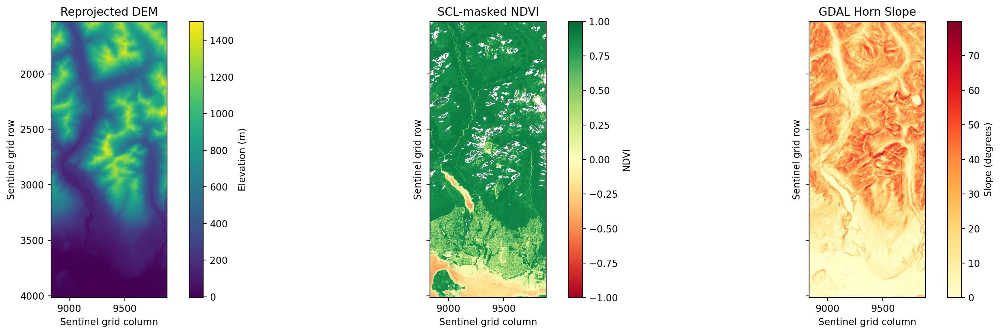

In [ ]:
plot_data = [
    (elev_crop, "Reprojected DEM", "viridis", "Elevation (m)", None, None),
    (ndvi_crop, "SCL-masked NDVI", "RdYlGn", "NDVI", -1, 1),
    (slope_gdal_array, "GDAL Horn Slope", "YlOrRd", "Slope (degrees)", 0, None),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=200, sharex=True, sharey=True)

for ax, (data, title, cmap, colorbar_label, vmin, vmax) in zip(axes, plot_data):
    image = ax.imshow(
        np.ma.masked_invalid(data),
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        extent=extent,
        origin="upper",
    )
    ax.set_title(title)
    ax.set_xlabel("Sentinel grid column")
    ax.set_ylabel("Sentinel grid row")
    fig.colorbar(image, ax=ax, label=colorbar_label)

fig.tight_layout()
plt.show()

In [ ]:
# Raster Flattening and Valid Data Extraction
ndvi_crop_flat = ndvi_crop.ravel()
elev_crop_flat = elev_crop.ravel()
slope_crop_flat = slope_gdal_array.ravel()

valid_ndvi_crop = ndvi_crop_flat[np.isfinite(ndvi_crop_flat)]
valid_elev_crop = elev_crop_flat[np.isfinite(elev_crop_flat)]
valid_slope_crop = slope_crop_flat[np.isfinite(slope_crop_flat)]

print("Flattened shapes:", ndvi_crop_flat.shape, elev_crop_flat.shape, slope_crop_flat.shape)
print("Independent valid counts:", valid_ndvi_crop.size, valid_elev_crop.size, valid_slope_crop.size)

In [ ]:
plot_data = [
    (valid_elev_crop, "Elevation Distribution", "Elevation (m)"),
    (valid_ndvi_crop, "NDVI Distribution", "NDVI"),
    (valid_slope_crop, "Slope Distribution", "Slope (degrees)"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), dpi=150)
for ax, (values, title, xlabel) in zip(axes, plot_data):
    ax.hist(values, bins=30)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")

fig.tight_layout()
plt.show()

In [ ]:
for name, values in [
    ("Elevation", valid_elev_crop),
    ("NDVI", valid_ndvi_crop),
    ("Slope", valid_slope_crop),
]:
    print(f"\n{name} statistics")
    print("Count:", values.size)
    print("Skew:", skew(values))
    print("Max:", np.max(values))
    print("Min:", np.min(values))
    print("Mean:", np.mean(values))
    print("Median:", np.median(values))
    print("Standard deviation:", np.std(values))

## Unsupervised Clustering using KMeans

In [1]:
# Data flattening and valid data extraction for combined analysis
ndvi_crop_flat = ndvi_crop.flatten()
elev_crop_flat = elev_crop.flatten()

print(ndvi_crop_flat.shape)
print(elev_crop_flat.shape)

valid_mask2 = (
    ~np.isnan(ndvi_crop_flat) &
    ~np.isnan(elev_crop_flat)
)

print(valid_mask2.shape)

valid_ndvi_crop = ndvi_crop_flat[valid_mask2]
valid_elev_crop = elev_crop_flat[valid_mask2]

print(ndvi_crop.shape)
print(elev_crop.shape)

ndvi_elevation_combined = np.column_stack((valid_ndvi_crop, valid_elev_crop))
print(ndvi_elevation_combined.shape)

NameError: name 'ndvi_crop' is not defined

In [ ]:
# Model Fitting and Clustering
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
ndvi_elevation_combined_scaled = scaler.fit_transform(ndvi_elevation_combined)

model_ndvi_elev = KMeans(n_clusters=4)
model_ndvi_elev.fit(ndvi_elevation_combined_scaled)

model_ndvi_elev.cluster_centers_
centers2 = model_ndvi_elev.cluster_centers_.flatten()
print(centers2)


labels2 = model_ndvi_elev.labels_
np.unique(labels2, return_counts=True)

In [ ]:
# K-means feature order is [NDVI, elevation]
centers_scaled = model_ndvi_elev.cluster_centers_
centers_original = scaler.inverse_transform(centers_scaled)

centers_df = pd.DataFrame({
    "cluster": np.arange(len(centers_scaled)),
    "NDVI_center_z": centers_scaled[:, 0],
    "elevation_center_z": centers_scaled[:, 1],
    "NDVI_center": centers_original[:, 0],
    "elevation_center_m": centers_original[:, 1],
})

# Summarize the actual pixels assigned to each cluster
pixel_stats = (
    pd.DataFrame({
        "cluster": labels2,
        "NDVI": valid_ndvi_crop,
        "elevation_m": valid_elev_crop,
    })
    .groupby("cluster")
    .agg(
        pixel_count=("NDVI", "size"),
        NDVI_mean=("NDVI", "mean"),
        NDVI_median=("NDVI", "median"),
        elevation_mean_m=("elevation_m", "mean"),
        elevation_median_m=("elevation_m", "median"),
    )
    .reset_index()
)

cluster_summary = centers_df.merge(pixel_stats, on="cluster")
print(cluster_summary.round(3))


In [ ]:
cluster_raster2 = np.full(ndvi_crop.shape, np.nan)

valid_mask_2d = valid_mask2.reshape(ndvi_crop.shape)

cluster_raster2[valid_mask_2d] = labels2

plt.figure(figsize=(10, 6), dpi=150)

plt.imshow(cluster_raster2)
plt.title("KMeans NDVI Clusters")
plt.xlabel("Column")
plt.ylabel("Row")
plt.colorbar(label="Cluster")

plt.show()

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# 1. Calculate Pearson correlation coefficient
r, p = pearsonr(valid_elev_crop, valid_ndvi_crop)
print(f"Pearson r: {r}, p-value: {p}")

# 2. Extract scaled data columns
scaled_elevation = ndvi_elevation_combined_scaled[:, 0]
scaled_ndvi = ndvi_elevation_combined_scaled[:, 1]

# 3. Create a 1-row, 2-column figure layout
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=150)

# --- LEFT PLOT: Original Units ---
im1 = axes[0].scatter(
    valid_ndvi_crop,
    valid_elev_crop,
    c=labels2,
    s=1,
    cmap="tab10"
)
axes[0].set_xlabel("NDVI")
axes[0].set_ylabel("Elevation (m)")
axes[0].set_title(f"K-means clusters: NDVI & Elevation\n(Pearson r = {r:.3f})")

# Add colorbar to the first plot
cbar1 = fig.colorbar(im1, ax=axes[0])
cbar1.set_label("Cluster ID")


# --- RIGHT PLOT: Scaled Data ---
im2 = axes[1].scatter(
    scaled_ndvi,
    scaled_elevation,
    c=labels2,
    s=1,
    cmap="tab10"  # Kept the same colormap for consistency
)
axes[1].set_xlabel("Scaled NDVI")
axes[1].set_ylabel("Scaled Elevation")
axes[1].set_title("K-means clusters: Scaled Data")

# Add colorbar to the second plot
cbar2 = fig.colorbar(im2, ax=axes[1])
cbar2.set_label("Cluster ID")

# Fix formatting layouts and render
plt.tight_layout()
plt.show()


In [ ]:
df = pd.DataFrame({
    "elevation_m": valid_elev_crop,
    "NDVI": valid_ndvi_crop,
})

df["elevation_band"] = pd.cut(df["elevation_m"], bins=10)
print(df.groupby("elevation_band", observed=True)["NDVI"].agg(
    ["count", "mean", "median", "std"]
))

## Statistical Analysis, ML, FFTS, Monte Carlo ??

In [ ]:
print(ndvi_clean_mask.shape)
ndvi_clean_mask_flat = ndvi_clean_mask.flatten()
valid_mask = ~np.isnan(ndvi_clean_mask_flat)
valid_ndvi = ndvi_clean_mask_flat[valid_mask]
print(np.isnan(valid_ndvi).sum())

plt.hist(valid_ndvi, bins=20)
plt.show()

In [ ]:
import numpy as np
from scipy import stats

# 1. Compute the histogram from your NDVI data
counts, bins = np.histogram(valid_ndvi, bins=20)

# Find the index of the highest peak (the most populated bin)
max_bin_idx = np.argmax(counts)

# DYNAMICALLY ASSIGN bin_start and bin_end based on that peak index
bin_start = bins[max_bin_idx]
bin_end = bins[max_bin_idx + 1]

# 2. Filter your ORIGINAL raw data to only keep values inside this bin
bin_data = valid_ndvi[(valid_ndvi >= bin_start) & (valid_ndvi < bin_end)]

# 3. Find the most common exact value (mode) within that subset
# Added a fallback check in case a bin happens to be empty to avoid index errors
if len(bin_data) > 0:
    mode_result = stats.mode(bin_data, keepdims=True)
    most_common_value = mode_result.mode[0]
    frequency = mode_result.count[0]

    print(f"Most populated bin index: {max_bin_idx}")
    print(f"The range is: [{bin_start:.4f} to {bin_end:.4f}]")
    print(f"The most common exact value in this bin is {most_common_value} (appears {frequency} times).")
else:
    print(f"The bin range [{bin_start:.2f} - {bin_end:.2f}] contains no data points.")


In [ ]:
reshaped_ndvi = valid_ndvi.reshape(-1, 1) # samples and features  
print(reshaped_ndvi.shape)

In [ ]:
from sklearn.cluster import KMeans

model = KMeans(n_clusters=4)the 
model.fit(reshaped_ndvi)

In [ ]:
model.cluster_centers_
centers = model.cluster_centers_.flatten()
print(centers)

labels = model.labels_
np.unique(labels, return_counts=True)

In [ ]:
cluster_ids, counts = np.unique(labels, return_counts=True)

print(cluster_ids)
print(counts)

percent = counts / counts.sum() * 100
print(percent)

In [57]:
cluster_raster = np.full(ndvi_clean_mask.shape, np.nan)

valid_mask = ~np.isnan(ndvi_clean_mask)

cluster_raster[valid_mask] = labels

plt.figure(figsize=(10, 6), dpi=150)

plt.imshow(cluster_raster)
plt.title("KMeans NDVI Clusters")
plt.xlabel("Column")
plt.ylabel("Row")
plt.colorbar(label="Cluster")

plt.show()

NameError: name 'ndvi_clean_mask' is not defined

In [ ]:
rows = slice(0, ndvi_clean_mask.shape[0] // 2)
cols = slice(0, ndvi_clean_mask.shape[1] // 2)

ndvi_subset = ndvi_clean_mask[:500, -500:]
cluster_subset = cluster_raster[:500, -500:]



fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=200)

# Original SCL-masked NDVI
im1 = axes[0].imshow(
    ndvi_subset,
    cmap="viridis",
    vmin=-1,
    vmax=1
)

axes[0].set_title("SCL-Masked NDVI")
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Row")
fig.colorbar(im1, ax=axes[0], label="NDVI")


# KMeans clusters
im2 = axes[1].imshow(
    cluster_subset,
    cmap="viridis"
)

axes[1].set_title("KMeans NDVI Clusters")
axes[1].set_xlabel("Column")
axes[1].set_ylabel("Cluster")
fig.colorbar(im2, ax=axes[1], label="Cluster")

plt.tight_layout()
plt.show()

## NDVI Rasters and Combined Rasters ??

In [ ]:
ndvi_valid_under_0 = np.where(
    ndvi_crop < 0,
    ndvi_crop,
    np.nan
)

print(ndvi_valid_under_0.shape)


ndvi_valid_0_0_5 = np.where(
    (ndvi_crop >= 0) & (ndvi_crop < 0.5),
    ndvi_crop,
    np.nan
)

ndvi_valid_0_5_1 = np.where(
    (ndvi_crop >= 0.5) & (ndvi_crop < 1),
    ndvi_crop,
    np.nan
)

ndvi_valid_greater_1 = np.where(
    ndvi_crop >= 1,
    ndvi_crop,
    np.nan
)

In [ ]:
ndvi_labels = [
    "NDVI < 0",
    "NDVI 0–0.5",
    "NDVI 0.5–1",
    "NDVI > 1"
]

ndvi_rasters = [
    ndvi_valid_under_0,
    ndvi_valid_0_0_5,
    ndvi_valid_0_5_1,
    ndvi_valid_1
]

fig, axes = plt.subplots(1, 4, figsize=(18, 6), dpi=200)

for ax, ndvi_data, label in zip(axes, ndvi_rasters, ndvi_labels):

    im = ax.imshow(ndvi_data, cmap="viridis")

    ax.set_title(label)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("NDVI")
plt.tight_layout()
plt.show()

In [ ]:
elevation_crop_valid_under_500 = np.where(
    elev_crop< 500,
    elev_crop,
    np.nan
)

elevation_crop_valid_500_1000 = np.where(
    (elev_crop >= 500) & (elev_crop < 1000),
    elev_crop,
    np.nan
)

elevation_crop_valid_1000_1500 = np.where(
    (elev_crop >= 1000) & (elev_crop < 1500),
    elev_crop,
    np.nan
)

elevation_crop_valid_over_1500 = np.where(
    elev_crop >= 1500,
    elev_crop,
    np.nan
)

In [ ]:
elevation_labels = [
    "elevation < 500 m",
    "elevation 500–1000 m",
    "elevation 1000–1500 m",    
    "elevation > 1500 m"
]

elevation_rasters = [
    elevation_crop_valid_under_500,
    elevation_crop_valid_500_1000,
    elevation_crop_valid_1000_1500,
    elevation_valid_over_1500
]

fig, axes = plt.subplots(1, 4, figsize=(18, 6), dpi=200)

for ax, elevation_data, label in zip(axes, elevation_rasters, elevation_labels):

    im = ax.imshow(elevation_data, cmap="viridis")

    ax.set_title(label)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Elevation (m)")
plt.tight_layout()
plt.show()

In [ ]:
# Combined Rasters 

params_ndvi = [ndvi_valid_under_0, ndvi_valid_0_0_5, ndvi_valid_0_5_1, ndvi_valid_greater_1]
params_elevation_crop = [elevation_crop_valid_under_500, elevation_crop_valid_500_1000, elevation_crop_valid_1000_1500, elevation_crop_valid_over_1500]
elevation_crop_rasters = []
ndvi_rasters = []

for ndvi_layer in params_ndvi:
    for elevation_crop_layer in params_elevation_crop:

        valid_new_crop_mask = ~np.isnan(ndvi_layer) & ~np.isnan(elevation_crop_layer)

        ndvi_mask = np.where(valid_new_crop_mask, ndvi_layer, np.nan)
        ndvi_rasters.append(ndvi_mask)

        elevation_crop_mask = np.where(valid_new_crop_mask, elevation_crop_layer, np.nan)
        elevation_crop_rasters.append(elevation_crop_mask)


In [ ]:

ndvi_labels = ["ndvi < 0", "ndvi 0–0.5", "ndvi 0.5–1", "ndvi > 1"]
elevation_crop_labels = ["Elev < 500m", "Elev 500m-1000m", "Elev 1000m-1500m", "Elev > 1500m"]

index = 0

for s_label in ndvi_labels:
    for e_c_label in elevation_crop_labels:

        elevation_crop_data = elevation_crop_rasters[index]
        ndvi_data = ndvi_rasters[index]

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

        # Elevation Plots
        im1 = ax1.imshow(elevation_crop_data, cmap='viridis')
        ax1.set_title(f"Elevation Profile\n({s_label} & {e_c_label})", fontsize=12)
        ax1.set_xlabel("X Coordinate (pixels)")
        ax1.set_ylabel("Y Coordinate (pixels)")
        cbar1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
        cbar1.set_label("Elevation (m)") 

        # NDVI Plots
        im2 = ax2.imshow(ndvi_data, cmap='viridis')
        ax2.set_title(f"NDVI Profile\n({s_label} & {e_c_label})", fontsize=12)
        ax2.set_xlabel("X Coordinate (pixels)")
        # Y label is omitted automatically because sharey=True simplifies the layout

        cbar2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
        cbar2.set_label("NDVI") 

        plt.tight_layout()
        plt.show()

        index += 1

## Export NDVI TRaster and Elevation Raster

## Temporal Study 3 Months

## Additional TO DO

- Cleanup/writeup
- Clean band exports
- Clean stats
- Temporal
- Redo Blender
- ML with open land labels? 
- are the pixels actually aligned?? 

- ML polygons
- shadow correction? CC=correct the ndvi
- landsat 
- runoffs

## Dynamic World Land Cover

In [ ]:
import ee 

ee.Authenticate()
ee.Initialize(project="gis-project-510419")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [ ]:
print("Red band bounds:", red_src.bounds)
print("Red band CRS:", red_src.crs)

west_l2a, south_l2a, east_l2a, north_l2a = red_src.bounds
print("Bounding box coordinates:")
print("West:", west_l2a)
print("South:", south_l2a)
print("East:", east_l2a)
print("North:", north_l2a)

# Transform Coordinates
transformer_l2a = Transformer.from_crs(
    red_src.crs,
    "EPSG:4326",  
    always_xy=True
)

lon_west, lat_south = transformer_l2a.transform(west_l2a, south_l2a)
print(west_l2a, south_l2a)
print(lon_west, lat_south)

lon_east, lat_north = transformer_l2a.transform(east_l2a, north_l2a)
print(east_l2a, north_l2a)
print(lon_east, lat_north)


Red band bounds: BoundingBox(left=399960.0, bottom=5390220.0, right=509760.0, top=5500020.0)
Red band CRS: EPSG:32610
Bounding box coordinates:
West: 399960.0
South: 5390220.0
East: 509760.0
North: 5500020.0
399960.0 5390220.0
-124.35845377491248 48.65702077458387
509760.0 5500020.0
-122.86478640421983 49.65264386827533


In [ ]:
aoi = ee.Geometry.Rectangle([
    lon_west,
    lat_south,
    lon_east,
    lat_north
])

In [ ]:
dw = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterDate("2026-09-18", "2026-09-19")
    .filterBounds(aoi)
)

print("Number of images:", dw.size().getInfo())
print("Images:")
print(dw.aggregate_array("system:index").getInfo())

In [ ]:
dw_image = dw.filter(
    ee.Filter.eq(
        "system:index",
        "20260918T191831_20260918T191827_T10UDV"
    )
).first()

print(dw_image.getInfo()["id"])
print(dw_image.bandNames().getInfo())

In [ ]:
dw_label = dw_image.select("label")

task = ee.batch.Export.image.toDrive(
    image=dw_label,
    description="dynamic_world_20260918_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="dynamic_world_20260918_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task.start()

print("Export started")

In [ ]:
print(task.status())

In [ ]:
dynamic_world_tif_path = r"Dynamic_World_tif\dynamic_world_20260918_T10UDV.tif"
src = rasterio.open(dynamic_world_tif_path)

# Raster Metadata
with rasterio.open(dynamic_world_tif_path) as dw_src:
    print("CRS:", dw_src.crs)
    print("Bounds:", dw_src.bounds)
    print("Width:", dw_src.width)
    print("Height:", dw_src.height)
    print(dw_src.tags())
    #print(dw_src.crs.to_wkt())
    print("Resolution:", dw_src.res)
    print("NoData value:", dw_src.nodata)
    print("Transform:", dw_src.transform)

    dw_bounds_4326 = transform_bounds(
        dw_src.crs,
        "EPSG:4326",
        *dw_src.bounds
    )

    print("WGS84 bounds:", dw_bounds_4326)

    dw_data = dw_src.read(1)

CRS: EPSG:32610
Bounds: BoundingBox(left=399950.0, bottom=5389330.0, right=509960.0, top=5500900.0)
Width: 11001
Height: 11157
{'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
WGS84 bounds: (-124.38609081028761, 48.649014843483585, -122.86199326082338, 49.66063805144947)


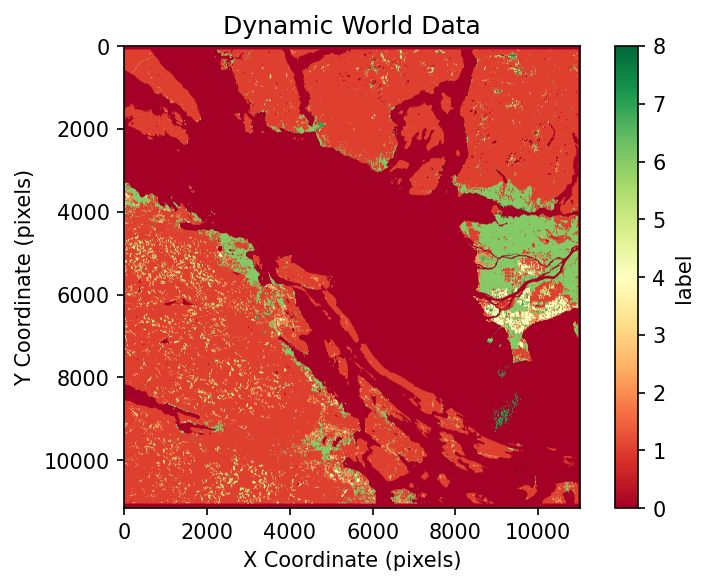

In [ ]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(dw_data, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("Dynamic World Data")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

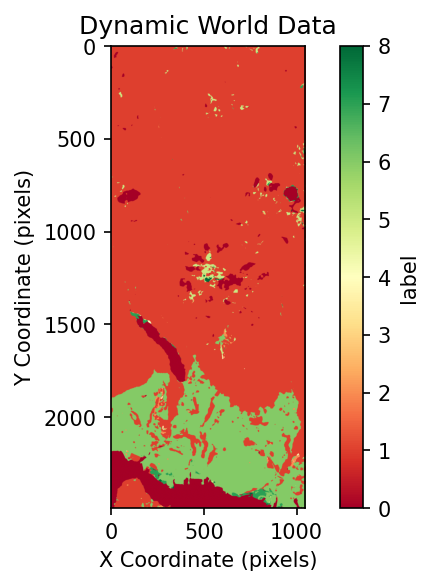

In [ ]:
dw_crop = dw_data[row0:row1, col0:col1]

# Data Plot
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(dw_crop, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("Dynamic World Data")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

# Landsat

In [ ]:
landsat = (
    ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterDate("2026-09-14", "2026-09-19")
    .filterBounds(aoi)
    .filter(ee.Filter.lte("CLOUD_COVER", 30))
)

landsat_list = landsat.toList(landsat.size())


print("Number of images:", landsat.size().getInfo())
print("Images:")
print(landsat.aggregate_array("system:index").getInfo())

Number of images: 1
Images:
['LC09_048026_20260915']


In [ ]:
landsat_image = landsat.filter(
    ee.Filter.eq(
        "system:index",
        "LC09_048026_20260915"
    )
).first()

print(landsat_image.getInfo()["id"])
print(landsat_image.bandNames().getInfo())

LANDSAT/LC09/C02/T1_L2/LC09_048026_20260915
['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'SR_QA_AEROSOL', 'ST_B10', 'ST_ATRAN', 'ST_CDIST', 'ST_DRAD', 'ST_EMIS', 'ST_EMSD', 'ST_QA', 'ST_TRAD', 'ST_URAD', 'QA_PIXEL', 'QA_RADSAT']


In [ ]:
img_landsat = ee.Image("LANDSAT/LC09/C02/T1_L2/LC09_048026_20260915")   # your scene ID
print(img_landsat.propertyNames().getInfo())          # list everything available
print(img_landsat.get("CLOUD_COVER").getInfo())       # whole-scene cloud cover (%)
print(img_landsat.get("CLOUD_COVER_LAND").getInfo())  # land-only cloud cover (%)
print(img_landsat.get("DATE_ACQUIRED").getInfo(), img_landsat.get("SPACECRAFT_ID").getInfo())

['DATA_SOURCE_ELEVATION', 'WRS_TYPE', 'system:id', 'REFLECTANCE_ADD_BAND_1', 'REFLECTANCE_ADD_BAND_2', 'DATUM', 'REFLECTANCE_ADD_BAND_3', 'REFLECTANCE_ADD_BAND_4', 'REFLECTANCE_ADD_BAND_5', 'REFLECTANCE_ADD_BAND_6', 'REFLECTANCE_ADD_BAND_7', 'system:footprint', 'REFLECTIVE_SAMPLES', 'system:version', 'GROUND_CONTROL_POINTS_VERSION', 'SUN_AZIMUTH', 'needs_reingestion', 'UTM_ZONE', 'DATE_ACQUIRED', 'ELLIPSOID', 'system:time_end', 'DATA_SOURCE_PRESSURE', 'LANDSAT_PRODUCT_ID', 'STATION_ID', 'TEMPERATURE_ADD_BAND_ST_B10', 'DATA_SOURCE_REANALYSIS', 'REFLECTANCE_MULT_BAND_7', 'system:time_start', 'REFLECTANCE_MULT_BAND_6', 'L1_PROCESSING_LEVEL', 'PROCESSING_SOFTWARE_VERSION', 'L1_DATE_PRODUCT_GENERATED', 'EPHEMERIS_TYPE', 'ORIENTATION', 'REFLECTANCE_MULT_BAND_1', 'WRS_ROW', 'REFLECTANCE_MULT_BAND_3', 'REFLECTANCE_MULT_BAND_2', 'TARGET_WRS_ROW', 'REFLECTANCE_MULT_BAND_5', 'REFLECTANCE_MULT_BAND_4', 'THERMAL_LINES', 'GRID_CELL_SIZE_THERMAL', 'IMAGE_QUALITY_TIRS', 'NADIR_OFFNADIR', 'CLOUD_COVER'

In [ ]:
landsat_label = landsat_image.select("label")

task_2 = ee.batch.Export.image.toDrive(
    image=landsat_label,
    description="LC09_048026_20260915",
    folder="EarthEngine",
    fileNamePrefix="LC09_048026_20260915",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_2.start()
print("Export started")

In [ ]:
print(task_2.status())

In [ ]:
landsat_tif_path = r"landsat\LC09_048026_20260915.tif"
src = rasterio.open(landsat_tif_path)

# Raster Metadata
with rasterio.open(landsat_tif_path) as landsat_src:
    landsat_data = landsat_src.read(1)
    landsat_transform = landsat_src.transform
    landsat_crs = landsat_src.crs
    landsat_nodata = landsat_src.nodata
    
    print("CRS:", landsat_src.crs)
    print("Bounds:", landsat_src.bounds)
    print("Width:", landsat_src.width)
    print("Height:", landsat_src.height)
    print(landsat_src.tags())
    #print(landsat_src.crs.to_wkt())
    print("Resolution:", landsat_src.res)
    print("NoData value:", landsat_src.nodata)
    print("Transform:", landsat_src.transform)
    print(landsat_src.descriptions)

    landsat_bounds_4326 = transform_bounds(
        landsat_src.crs,
        "EPSG:4326",
        *landsat_src.bounds
    )

    print("WGS84 bounds:", landsat_bounds_4326)

    landsat_data = landsat_src.read(1)
    print(landsat_data.shape)

    # check
    print("Dataset NoData:", landsat_src.nodata)

    for i, description in enumerate(landsat_src.descriptions, start=1):
        print(
            i,
            description,
            "dtype:", landsat_src.dtypes[i - 1],
         "NoData:", landsat_src.nodatavals[i - 1],
         "mask flags:", landsat_src.mask_flag_enums[i - 1]
        )

CRS: EPSG:32610
Bounds: BoundingBox(left=399930.0, bottom=5389320.0, right=509970.0, top=5500920.0)
Width: 3668
Height: 3720
{'AREA_OR_POINT': 'Area'}
Resolution: (30.0, 30.0)
NoData value: None
Transform: | 30.00, 0.00, 399930.00|
| 0.00,-30.00, 5500920.00|
| 0.00, 0.00, 1.00|
('ST_B10', 'ST_QA', 'QA_PIXEL', 'SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7')
WGS84 bounds: (-124.38637291345228, 48.648921704997804, -122.86185419097141, 49.66081794355603)
(3720, 3668)
Dataset NoData: None
1 ST_B10 dtype: uint16 NoData: None mask flags: [<MaskFlags.all_valid: 1>]
2 ST_QA dtype: uint16 NoData: None mask flags: [<MaskFlags.all_valid: 1>]
3 QA_PIXEL dtype: uint16 NoData: None mask flags: [<MaskFlags.all_valid: 1>]
4 SR_B1 dtype: uint16 NoData: None mask flags: [<MaskFlags.all_valid: 1>]
5 SR_B2 dtype: uint16 NoData: None mask flags: [<MaskFlags.all_valid: 1>]
6 SR_B3 dtype: uint16 NoData: None mask flags: [<MaskFlags.all_valid: 1>]
7 SR_B4 dtype: uint16 NoData: None mask flags: [

In [ ]:
# Data Cleaning
with rasterio.open(landsat_tif_path) as landsat_src:
    surface_temp_DN = landsat_src.read(1)
    surface_temp_DN_unc = landsat_src.read(2)
    QA_pixel = landsat_src.read(3)
        
print("surface_temp_DN zeros:", np.sum(surface_temp_DN == 0))
print("surface_temp_DN totals:", surface_temp_DN.size)
print("surface_temp_DN non-zeros:", surface_temp_DN.size - np.sum(surface_temp_DN == 0))
print("surface_temp_DN_nodata:", landsat_nodata)

surface_temp_DN zeros: 1233589
surface_temp_DN totals: 13644960
surface_temp_DN non-zeros: 12411371
surface_temp_DN_nodata: None


In [ ]:
special_value_surface_temp_DN = 0
valid_surface_temp_DN_mask = surface_temp_DN != special_value_surface_temp_DN
valid_surface_temp_DN = np.where(
    valid_surface_temp_DN_mask, 
    surface_temp_DN, 
    np.nan)

valid_surface_temp_C = (valid_surface_temp_DN * 0.00341802 + 149.0) - 273.15
print(np.nanmin(valid_surface_temp_C), np.nanmax(valid_surface_temp_C))

-38.30984572 46.405779980000034


In [ ]:
print("QA_pixel zeros:", np.sum(QA_pixel == 0))
print("QA_pixel other:", np.sum(QA_pixel == np.max(QA_pixel)))
print(np.max(QA_pixel), np.min(QA_pixel))

#cloud_mask = (QA_pixel & (1 << 3)) != 0

bad_bits = (
    (1 << 0) | # Fill
    (1 << 1) | # Dilated Cloud
    (1 << 2) | # Cirrus
    (1 << 3) | # Cloud
    (1 << 4) # Cloud Shadow
) 

bad_pixels = (QA_pixel & bad_bits) != 0

surface_temp_C_bit_mask = np.where(
    bad_pixels,
    np.nan,
    valid_surface_temp_C
)

print("Cloud-masked surface_temp_C zeros:", np.sum(np.isnan(surface_temp_C_bit_mask)))
print(np.nanmax(surface_temp_C_bit_mask), np.nanmin(surface_temp_C_bit_mask))
print("Flagged pixels:", np.sum(bad_bits))
print("Temperature values before:", np.sum(np.isfinite(valid_surface_temp_C)))
print("Temperature values after:", np.sum(np.isfinite(surface_temp_C_bit_mask)))

QA_pixel zeros: 1233483
QA_pixel other: 1
63014 0
Cloud-masked surface_temp_C zeros: 6584721
46.405779980000034 -7.158011439999996
Flagged pixels: 31
Temperature values before: 12411371
Temperature values after: 7060239


In [ ]:
before = np.isfinite(valid_surface_temp_C).sum()
after = np.isfinite(surface_temp_C_bit_mask).sum()

print("Valid pixels before:", before)
print("Valid pixels after:", after)
print("Pixels removed:", before - after)
print("Percent retained:", 100 * after / before)

Valid pixels before: 12411371
Valid pixels after: 7060239
Pixels removed: 5351132
Percent retained: 56.885246601684855


In [ ]:
print("Min:", np.nanmin(surface_temp_C_bit_mask))
print("Max:", np.nanmax(surface_temp_C_bit_mask))
print("Median:", np.nanmedian(surface_temp_C_bit_mask))
print(np.nanpercentile(surface_temp_C_bit_mask, [5, 50, 95]))

Min: -7.158011439999996
Max: 46.405779980000034
Median: 16.111868720000018
[13.79103314 16.11186872 25.19354786]


In [ ]:
for bit in range(5):
    flag = (QA_pixel & (1 << bit)) != 0
    print(f"Bit {bit}: {np.sum(flag)} pixels")

print("Combined flagged:", np.sum(bad_pixels))
print("Total pixels:", QA_pixel.size)
print("Retained temperature pixels:",
      np.isfinite(surface_temp_C_bit_mask).sum())

Bit 0: 0 pixels
Bit 1: 1015399 pixels
Bit 2: 212221 pixels
Bit 3: 3409849 pixels
Bit 4: 1530057 pixels
Combined flagged: 5351238
Total pixels: 13644960
Retained temperature pixels: 7060239


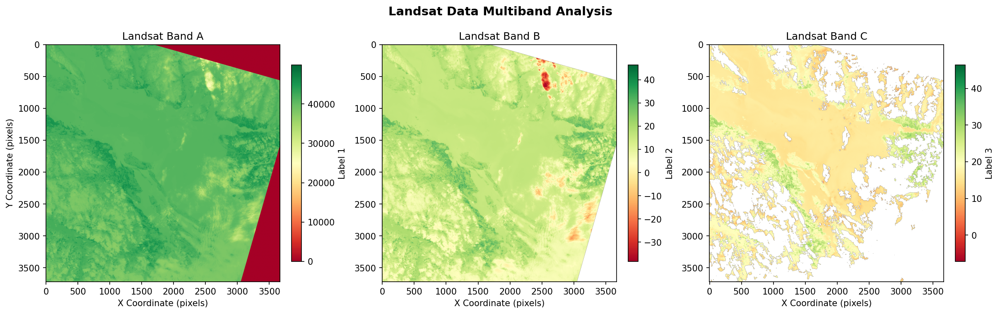

In [ ]:
import matplotlib.pyplot as plt

# 1. Create a 1x3 grid layout
# figsize=(16, 5) gives each image ample room while preserving a wide aspect ratio
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(16, 5), dpi=150, constrained_layout=True)
fig.suptitle("Landsat Data Multiband Analysis", fontsize=14, fontweight='bold')

# --- COLUMN 1 ---
im1 = ax1.imshow(landsat_data, cmap="RdYlGn")  # Replace with your first data array
fig.colorbar(im1, ax=ax1, label="Label 1", orientation='vertical', shrink=0.7)
ax1.set_title("Landsat Band A")
ax1.set_xlabel("X Coordinate (pixels)")
ax1.set_ylabel("Y Coordinate (pixels)")

# --- COLUMN 2 ---
im2 = ax2.imshow(valid_surface_temp_C, cmap="RdYlGn")  # Replace with your second data array
fig.colorbar(im2, ax=ax2, label="Label 2", orientation='vertical', shrink=0.7)
ax2.set_title("Landsat Band B")
ax2.set_xlabel("X Coordinate (pixels)")
# Y-label can be omitted here if the coordinates align across plots

# --- COLUMN 3 ---
im3 = ax3.imshow(surface_temp_C_bit_mask, cmap="RdYlGn")  # Replace with your third data array
fig.colorbar(im3, ax=ax3, label="Label 3", orientation='vertical', shrink=0.7)
ax3.set_title("Landsat Band C")
ax3.set_xlabel("X Coordinate (pixels)")

# 2. Render the layout
plt.show()


In [ ]:
fp = np.isfinite(valid_surface_temp_C)
bits = {"fill": 0, "dilated":1, "cirrus":2, "cloud":3, "shadow":4}
flag = {n: ((QA_pixel >> b) & 1).astype(bool) & fp for n, b in bits.items()}
for n, f in flag.items():
    others = np.any([flag[m] for m in flag if m != n], axis=0)
    print(f"{n:8s} total {f.sum()/fp.sum():.1%}  only-this {(f & ~others).sum()/fp.sum():.1%}")

fill     total 0.0%  only-this 0.0%
dilated  total 8.2%  only-this 3.3%
cirrus   total 1.7%  only-this 0.0%
cloud    total 27.5%  only-this 25.8%
shadow   total 12.3%  only-this 7.5%


In [ ]:
from rasterio.warp import reproject, Resampling

landsat_10m = np.full(red_band.shape, np.nan, dtype=np.float32)

reproject(
    source=surface_temp_C_bit_mask,
    destination=landsat_10m,
    src_transform=landsat_transform,
    src_crs=landsat_crs,
    src_nodata=landsat_nodata,  # Capture landsat_src.nodata when reading the raster
    dst_transform=red_transform,
    dst_crs=red_crs,
    dst_nodata=np.nan,
    resampling=Resampling.nearest,
)

print(landsat_10m.shape)

(10980, 10980)


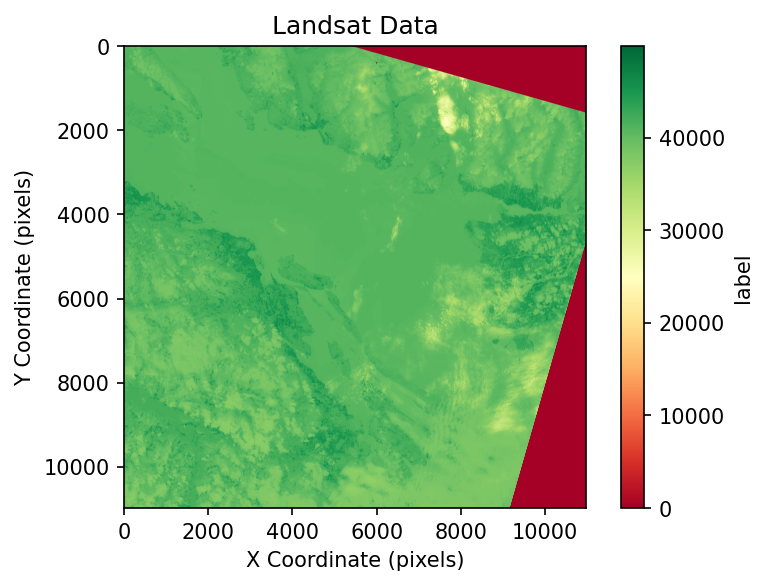

In [ ]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(landsat_10m, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("Landsat Data")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

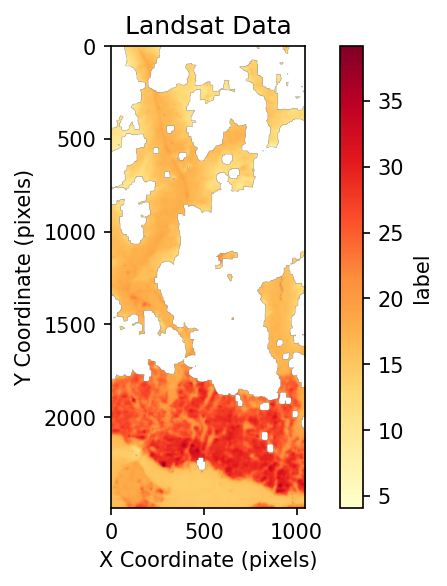

In [ ]:
landsat_crop = landsat_10m[row0:row1, col0:col1]

# Data Plot
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(landsat_crop, cmap="YlOrRd") 
plt.colorbar(label="label")
plt.title("Landsat Data")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

## Sentinel Different Method

In [ ]:
sentinel = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterDate("2026-09-17","2026-09-19")
    .filterBounds(aoi)
    .filter(ee.Filter.eq('MGRS_TILE', '10UDV'))
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 30))
)

print("Number of images:", sentinel.size().getInfo())
print("Images:")
print(sentinel.aggregate_array("system:index").getInfo())

sentinel_image = ee.Image(sentinel.first())
print(
    sentinel_image.toDictionary([
        'PRODUCT_ID',
        'system:index',
        'DATATAKE_IDENTIFIER',
        'MGRS_TILE',
        'CLOUDY_PIXEL_PERCENTAGE'
    ]).getInfo()
)

print(sentinel_image.bandNames().getInfo())


Number of images: 1
Images:
['20260918T191831_20260918T191827_T10UDV']
{'CLOUDY_PIXEL_PERCENTAGE': 0.051858, 'DATATAKE_IDENTIFIER': 'GS2A_20260918T191831_058712_N05.12', 'MGRS_TILE': '10UDV', 'PRODUCT_ID': 'S2A_MSIL2A_20260918T191831_N0512_R056_T10UDV_20260919T014720', 'system:index': '20260918T191831_20260918T191827_T10UDV'}
['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']


In [ ]:
sentinel_bands = (
    sentinel_image
    .select(["B4", "B8", "SCL"])
    .toUint16()
)

task_3 = ee.batch.Export.image.toDrive(
    image=sentinel_bands,
    description="sentinel_l2a_20260918T191831_20260918T191827_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="sentinel_l2a_20260918T191831_20260918T191827_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_3.start()
print("Export started")

Export started


In [ ]:
print(task_3.status())

{'state': 'COMPLETED', 'description': 'sentinel_l2a_20260918T191831_20260918T191827_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1791903884942, 'update_timestamp_ms': 1791904312024, 'start_timestamp_ms': 1791903887944, 'task_type': 'EXPORT_IMAGE', 'destination_uris': ['https://drive.google.com/#folders/16PMye91hB5cePcHjvv1Tr8_qE50-lc8r'], 'attempt': 1, 'batch_eecu_usage_seconds': 316.1261291503906, 'id': 'BYANXIX3NSZZWOCV35TOUMGW', 'name': 'projects/gis-project-510419/operations/BYANXIX3NSZZWOCV35TOUMGW'}


In [ ]:
sentinel_tif_path_1 = r"Datasets\sentinel_l2a_20260918T191831_20260918T191827_T10UDV.tif"

with rasterio.open(sentinel_tif_path_1) as sentinel_1_src:
    # Read each band
    sentinel_B4_R = sentinel_1_src.read(1)
    sentinel_B8_NIR = sentinel_1_src.read(2)
    sentinel_SCL = sentinel_1_src.read(3)

    # Dataset-level metadata are shared across bands, but assign them explicitly per band
    sentinel_B4_transform = sentinel_1_src.transform
    sentinel_B4_crs = sentinel_1_src.crs
    sentinel_B4_nodata = sentinel_1_src.nodatavals[0]
    sentinel_B4_shape = sentinel_B4_R.shape

    sentinel_B8_transform = sentinel_1_src.transform
    sentinel_B8_crs = sentinel_1_src.crs
    sentinel_B8_nodata = sentinel_1_src.nodatavals[1]
    sentinel_B8_shape = sentinel_B8_NIR.shape

    sentinel_SCL_transform = sentinel_1_src.transform
    sentinel_SCL_crs = sentinel_1_src.crs
    sentinel_SCL_nodata = sentinel_1_src.nodatavals[2]
    sentinel_SCL_shape = sentinel_SCL.shape

    # Optional: dataset metadata
    print("CRS:", sentinel_1_src.crs)
    print("Bounds:", sentinel_1_src.bounds)
    print("Width:", sentinel_1_src.width)
    print("Height:", sentinel_1_src.height)
    print("Tags:", sentinel_1_src.tags())
    print("Resolution:", sentinel_1_src.res)
    print("NoData value:", sentinel_1_src.nodata)
    print("Transform:", sentinel_1_src.transform)
    print("Descriptions:", sentinel_1_src.descriptions)

    sentinel_1_bounds_4326 = transform_bounds(
        sentinel_1_src.crs,
        "EPSG:4326",
        *sentinel_1_src.bounds
    )
    print("WGS84 bounds:", sentinel_1_bounds_4326)

    # Band-specific shapes
    print("B4 Red shape:", sentinel_B4_shape)
    print("B8 NIR shape:", sentinel_B8_shape)
    print("SCL shape:", sentinel_SCL_shape)

    # Band-specific stats
    print("B4 min/max:", np.min(sentinel_B4_R), np.max(sentinel_B4_R))
    print("B8 min/max:", np.min(sentinel_B8_NIR), np.max(sentinel_B8_NIR))
    print("SCL min/max:", np.min(sentinel_SCL), np.max(sentinel_SCL))

# Access outside the with block
print("B4 CRS:", sentinel_B4_crs)
print("B4 Transform:", sentinel_B4_transform)
print("B4 NoData:", sentinel_B4_nodata)
print("B4 Shape:", sentinel_B4_shape)

print("B8 CRS:", sentinel_B8_crs)
print("B8 Transform:", sentinel_B8_transform)
print("B8 NoData:", sentinel_B8_nodata)
print("B8 Shape:", sentinel_B8_shape)

print("SCL CRS:", sentinel_SCL_crs)
print("SCL Transform:", sentinel_SCL_transform)
print("SCL NoData:", sentinel_SCL_nodata)
print("SCL Shape:", sentinel_SCL_shape)

CRS: EPSG:32610
Bounds: BoundingBox(left=399950.0, bottom=5389330.0, right=509960.0, top=5500900.0)
Width: 11001
Height: 11157
Tags: {'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
Descriptions: ('B4', 'B8', 'SCL')
WGS84 bounds: (-124.38609081028761, 48.649014843483585, -122.86199326082338, 49.66063805144947)
B4 Red shape: (11157, 11001)
B8 NIR shape: (11157, 11001)
SCL shape: (11157, 11001)
B4 min/max: 0 16328
B8 min/max: 0 15723
SCL min/max: 0 11
B4 CRS: EPSG:32610
B4 Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
B4 NoData: None
B4 Shape: (11157, 11001)
B8 CRS: EPSG:32610
B8 Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
B8 NoData: None
B8 Shape: (11157, 11001)
SCL CRS: EPSG:32610
SCL Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
SCL NoData: None
SCL Shape: (11157, 110

In [ ]:
print(np.max( sentinel_B4_R), np.min( sentinel_B4_R))
print(np.count_nonzero(sentinel_B4_R == np.max( sentinel_B4_R)), np.count_nonzero( sentinel_B4_R == 0))


16328 0
2 2266433


In [ ]:
bad_classes_2 = [1, 3, 8, 9, 10, 11]
SCL_clear_mask = ~np.isin(sentinel_SCL, bad_classes_2)

SCL_valid_mask = np.where(
    np.isin(sentinel_SCL, bad_classes_2),
    False,
    np.isfinite(sentinel_B4_R) & np.isfinite(sentinel_B8_NIR)
)

sentinel_B4_R_mask = np.where(
    SCL_valid_mask,
    sentinel_B4_R,
    np.nan
)

sentinel_B8_NIR_mask = np.where(
    SCL_valid_mask,
    sentinel_B8_NIR,
    np.nan
)

sentinel_B4_R_corrected = sentinel_B4_R_mask * 0.0001
sentinel_B8_NIR_corrected = sentinel_B8_NIR_mask * 0.0001


denom_2 = sentinel_B4_R_corrected + sentinel_B8_NIR_corrected
valid_reflectance_mask_2 = (
    np.isfinite(sentinel_B4_R_corrected)
    & np.isfinite(sentinel_B8_NIR_corrected)
    & (sentinel_B4_R_corrected >= 0)
    & (sentinel_B8_NIR_corrected >= 0)
    & (denom_2 > 1e-6)
)

# NDVI
ndvi_2 = np.full(sentinel_B4_shape, np.nan, dtype=np.float32)
np.divide(
    sentinel_B8_NIR_corrected - sentinel_B4_R_corrected,
    denom_2,
    out=ndvi_2,
    where=valid_reflectance_mask_2
)

ndvi_2_crop = ndvi_2[row0:row1, col0:col1]

NameError: name 'row0' is not defined

In [ ]:
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(ndvi_2, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("NDVI Crop 2 Data")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

NameError: name 'ndvi_2' is not defined

<Figure size 900x600 with 0 Axes>

## Temporal

In [ ]:
sentinel_2 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterDate("2025-09-14", "2025-09-21")
    .filterBounds(aoi)
    .filter(ee.Filter.eq('MGRS_TILE', '10UDV'))
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 30))
)

print("Number of images:", sentinel_2.size().getInfo())
print("Images:")
print(sentinel_2.aggregate_array("system:index").getInfo())

sentinel_2_image = ee.Image(sentinel_2.first())
print(
    sentinel_2_image.toDictionary([
        'PRODUCT_ID',
        'system:index',
        'DATATAKE_IDENTIFIER',
        'MGRS_TILE',
        'CLOUDY_PIXEL_PERCENTAGE'
    ]).getInfo()
)

print(sentinel_2_image.bandNames().getInfo())

Number of images: 1
Images:
['20250916T190929_20250916T191932_T10UDV']
{'CLOUDY_PIXEL_PERCENTAGE': 1.33771, 'DATATAKE_IDENTIFIER': 'GS2B_20250916T190929_044555_N05.11', 'MGRS_TILE': '10UDV', 'PRODUCT_ID': 'S2B_MSIL2A_20250916T190929_N0511_R056_T10UDV_20250916T230157', 'system:index': '20250916T190929_20250916T191932_T10UDV'}
['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']


In [ ]:
sentinel_3 = (
    ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterDate("2024-09-14", "2024-09-21")
    .filterBounds(aoi)
    .filter(ee.Filter.eq('MGRS_TILE', '10UDV'))
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 30))
)

print("Number of images:", sentinel_3.size().getInfo())
print("Images:")
print(sentinel_3.aggregate_array("system:index").getInfo())

sentinel_3_image = ee.Image(sentinel_3.first())
print(
    sentinel_3_image.toDictionary([
        'PRODUCT_ID',
        'system:index',
        'DATATAKE_IDENTIFIER',
        'MGRS_TILE',
        'CLOUDY_PIXEL_PERCENTAGE'
    ]).getInfo()
)

print(sentinel_3_image.bandNames().getInfo())

Number of images: 1
Images:
['20240919T192101_20240919T192444_T10UDV']
{'CLOUDY_PIXEL_PERCENTAGE': 24.062595, 'DATATAKE_IDENTIFIER': 'GS2A_20240919T192101_048287_N05.11', 'MGRS_TILE': '10UDV', 'PRODUCT_ID': 'S2A_MSIL2A_20240919T192101_N0511_R099_T10UDV_20240920T003548', 'system:index': '20240919T192101_20240919T192444_T10UDV'}
['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']


In [ ]:
sentinel_bands_3 = (
    sentinel_3_image
    .select(["B4", "B8", "SCL"])
    .toUint16()
)

task_3 = ee.batch.Export.image.toDrive(
    image=sentinel_bands_3,
    description="sentinel_l2a_20250916T190929_20250916T191932_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="sentinel_l2a_20250916T190929_20250916T191932_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_3.start()
print("Export started")


Export started


In [ ]:
print(task_3.status())

{'state': 'RUNNING', 'description': 'sentinel_l2a_20250916T190929_20250916T191932_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1791914951979, 'update_timestamp_ms': 1791915214163, 'start_timestamp_ms': 1791914992919, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'batch_eecu_usage_seconds': 159.825, 'id': 'QBPEE7QOLM3A6O4Z6PW4GK3D', 'name': 'projects/gis-project-510419/operations/QBPEE7QOLM3A6O4Z6PW4GK3D'}


In [ ]:
task_4 = ee.batch.Export.image.toDrive(
    image=sentinel_bands_3,
    description="sentinel_l2a_20240919T192101_20240919T192444_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="sentinel_l2a_20240919T192101_20240919T192444_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_4.start()
print("Export started")

Export started


In [ ]:
print(task_4.status())

{'state': 'READY', 'description': 'sentinel_l2a_20240919T192101_20240919T192444_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1791915293175, 'update_timestamp_ms': 1791915297957, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'NZXSXPHXXJCLQNMITVSWMAW4', 'name': 'projects/gis-project-510419/operations/NZXSXPHXXJCLQNMITVSWMAW4'}


In [ ]:
sentinel_2_tif_path = r"Datasets\sentinel_l2a_20250916T190929_20250916T191932_T10UDV.tif"

with rasterio.open(sentinel_2_tif_path) as sentinel_2_src:
    # Read each band from the Sentinel-2 multiband GeoTIFF
    sentinel_2_B4_R = sentinel_2_src.read(1)
    sentinel_2_B8_NIR = sentinel_2_src.read(2)
    sentinel_2_SCL = sentinel_2_src.read(3)

    # Dataset-level metadata are shared across the bands in the same file,
    # but assign them explicitly per band for clarity and downstream use
    sentinel_2_B4_transform = sentinel_2_src.transform
    sentinel_2_B4_crs = sentinel_2_src.crs
    sentinel_2_B4_nodata = sentinel_2_src.nodatavals[0]
    sentinel_2_B4_shape = sentinel_2_B4_R.shape

    sentinel_2_B8_transform = sentinel_2_src.transform
    sentinel_2_B8_crs = sentinel_2_src.crs
    sentinel_2_B8_nodata = sentinel_2_src.nodatavals[1]
    sentinel_2_B8_shape = sentinel_2_B8_NIR.shape

    sentinel_2_SCL_transform = sentinel_2_src.transform
    sentinel_2_SCL_crs = sentinel_2_src.crs
    sentinel_2_SCL_nodata = sentinel_2_src.nodatavals[2]
    sentinel_2_SCL_shape = sentinel_2_SCL.shape

    print("CRS:", sentinel_2_src.crs)
    print("Bounds:", sentinel_2_src.bounds)
    print("Width:", sentinel_2_src.width)
    print("Height:", sentinel_2_src.height)
    print("Tags:", sentinel_2_src.tags())
    print("Resolution:", sentinel_2_src.res)
    print("NoData value:", sentinel_2_src.nodata)
    print("Transform:", sentinel_2_src.transform)
    print("Descriptions:", sentinel_2_src.descriptions)

    sentinel_2_bounds_4326 = transform_bounds(
        sentinel_2_src.crs,
        "EPSG:4326",
        *sentinel_2_src.bounds
    )
    print("WGS84 bounds:", sentinel_2_bounds_4326)

    print("B4 Red shape:", sentinel_2_B4_shape)
    print("B8 NIR shape:", sentinel_2_B8_shape)
    print("SCL shape:", sentinel_2_SCL_shape)

    print("B4 min/max:", np.min(sentinel_2_B4_R), np.max(sentinel_2_B4_R))
    print("B8 min/max:", np.min(sentinel_2_B8_NIR), np.max(sentinel_2_B8_NIR))
    print("SCL min/max:", np.min(sentinel_2_SCL), np.max(sentinel_2_SCL))

# Access outside the with block
print("B4 CRS:", sentinel_2_B4_crs)
print("B4 Transform:", sentinel_2_B4_transform)
print("B4 NoData:", sentinel_2_B4_nodata)
print("B4 Shape:", sentinel_2_B4_shape)

print("B8 CRS:", sentinel_2_B8_crs)
print("B8 Transform:", sentinel_2_B8_transform)
print("B8 NoData:", sentinel_2_B8_nodata)
print("B8 Shape:", sentinel_2_B8_shape)

print("SCL CRS:", sentinel_2_SCL_crs)
print("SCL Transform:", sentinel_2_SCL_transform)
print("SCL NoData:", sentinel_2_SCL_nodata)
print("SCL Shape:", sentinel_2_SCL_shape)

CRS: EPSG:32610
Bounds: BoundingBox(left=399950.0, bottom=5389330.0, right=509960.0, top=5500900.0)
Width: 11001
Height: 11157
Tags: {'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
Descriptions: ('B4', 'B8', 'SCL')
WGS84 bounds: (-124.38609081028761, 48.649014843483585, -122.86199326082338, 49.66063805144947)
B4 Red shape: (11157, 11001)
B8 NIR shape: (11157, 11001)
SCL shape: (11157, 11001)
B4 min/max: 0 16296
B8 min/max: 0 15720
SCL min/max: 0 11
B4 CRS: EPSG:32610
B4 Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
B4 NoData: None
B4 Shape: (11157, 11001)
B8 CRS: EPSG:32610
B8 Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
B8 NoData: None
B8 Shape: (11157, 11001)
SCL CRS: EPSG:32610
SCL Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|
SCL NoData: None
SCL Shape: (11157, 110

In [ ]:
# Sentinel-2 L2A SCL masking + NDVI using the correct sentinel_2_* variable names
bad_classes_3 = [1, 3, 8, 9, 10, 11]

# Keep only pixels that are not in the bad SCL classes
SCL_valid_mask_2 = ~np.isin(sentinel_2_SCL, bad_classes_3)

# Mask red and NIR arrays using the valid SCL mask
sentinel_2_B4_R_mask = np.where(
    SCL_valid_mask_2,
    sentinel_2_B4_R,
    np.nan
)

sentinel_2_B8_NIR_mask = np.where(
    SCL_valid_mask_2,
    sentinel_2_B8_NIR,
    np.nan
)

# Convert Sentinel-2 L2A DN to reflectance (0-1 scale)
sentinel_2_B4_R_corrected = sentinel_2_B4_R_mask * 0.0001
sentinel_2_B8_NIR_corrected = sentinel_2_B8_NIR_mask * 0.0001

denom_3 = sentinel_2_B4_R_corrected + sentinel_2_B8_NIR_corrected
valid_reflectance_mask_3 = (
    np.isfinite(sentinel_2_B4_R_corrected)
    & np.isfinite(sentinel_2_B8_NIR_corrected)
    & (sentinel_2_B4_R_corrected >= 0)
    & (sentinel_2_B8_NIR_corrected >= 0)
    & (denom_3 > 1e-6)
)

# NDVI
ndvi_3 = np.full(sentinel_2_B4_shape, np.nan, dtype=np.float32)
np.divide(
    sentinel_2_B8_NIR_corrected - sentinel_2_B4_R_corrected,
    denom_3,
    out=ndvi_3,
    where=valid_reflectance_mask_3
)

# Crop to the same AOI if needed
ndvi_3_crop = ndvi_3[row0:row1, col0:col1]

NameError: name 'row0' is not defined

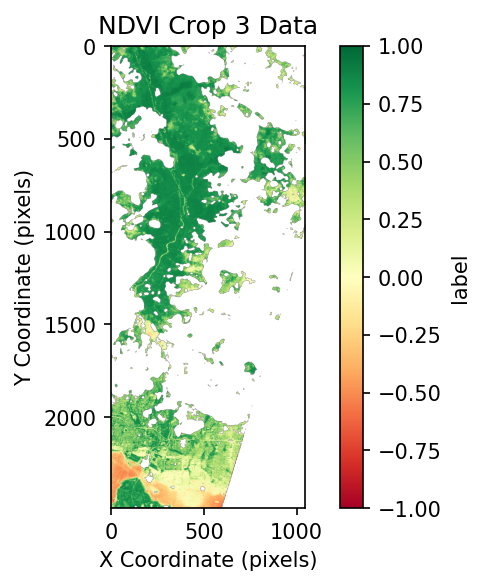

In [ ]:
plt.figure(figsize=(6, 4), dpi=150)
plt.imshow(ndvi_3_crop, cmap="RdYlGn") 
plt.colorbar(label="label")
plt.title("NDVI Crop 3 Data")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

In [ ]:
print("ndvi_2 shape:", ndvi_2.shape)
print("ndvi_3 shape:", ndvi_3.shape)
print("ndvi_2_crop shape:", ndvi_2_crop.shape)
print("ndvi_3_crop shape:", ndvi_3_crop.shape)
print("crop coords:", row0, row1, col0, col1)

ndvi_2 shape: (11157, 11001)
ndvi_3 shape: (11157, 11001)
ndvi_2_crop shape: (2490, 1046)
ndvi_3_crop shape: (2490, 1046)
crop coords: 1528 4018 8837 9883
